# Restaurant demand forecasting: foundation models vs. the classics

**Reading-group notebook.** Do pretrained *time-series foundation models* (TSFMs) beat
well-understood forecasting methods on restaurant demand? We can't share real sales data,
so we **simulate** daily store × item demand under several sets of assumptions, each built
to stress a different weakness, and run every method through the same backtest.

| Family | Methods | What it knows |
|---|---|---|
| Baseline | Seasonal naive (same weekday last week) | nothing |
| Classical, local (one model per series) | AutoETS (seasonal exponential smoothing), AutoARIMA (seasonal AR/MA processes), MSTL (weekly + yearly decomposition), Croston-SBA (intermittent demand) | its own history |
| ML, global (one model across series) | LightGBM quantile regression on lag/calendar/covariate features | all series + covariates |
| Bayesian hierarchical | Negative-binomial GLM with partial pooling across stores, items and store types, plus changepoints (PyMC/NUTS) | all series + covariates + structure we wrote down |
| Foundation models (zero-shot) | Chronos-Bolt, TimesFM 2.5, Chronos-2 (univariate, with covariates, with cross-learning) | pretraining corpus + the context we give it |
| Reference | Oracle: the true simulated mean and noise distribution | the data-generating process |

The **oracle** marks the irreducible noise floor: no method can beat it on average, so it
shows how much room is left.

**Reading pointers**
- Chronos: Ansari et al., *Chronos: Learning the Language of Time Series* (2024), arXiv:2403.07815
- Chronos-2: Ansari et al., *Chronos-2: From Univariate to Universal Forecasting* (2025), arXiv:2510.15821
- TimesFM: Das et al., *A decoder-only foundation model for time-series forecasting* (ICML 2024), arXiv:2310.10688
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.), on ETS, ARIMA, MSTL and accuracy measures
- Makridakis et al., *M5 accuracy competition* (2022), where LightGBM global models won on retail data

**Section 0** is a primer on how TSFMs work. Sections 1–6 cover five everyday scenarios.
**Section 7 is a set of stress tests**: data built to
make the foundation models fail, with hypotheses written down before each run. Several of the
hypotheses turned out to be wrong.

> Running the whole backtest from scratch takes about 1.5 hours on a laptop CPU, mostly for
> the Bayesian model. Forecasts are cached in `results/`, so re-running the notebook only
> re-scores and re-plots them. Set `FAST=1` in the environment for a quick smoke-test run.

## 0. Primer: what is a time-series foundation model?

A **time-series foundation model (TSFM)** is one large neural network pretrained on a very wide
collection of time series (energy, traffic, weather, retail, web traffic and more, plus a lot of
synthetic data). It can forecast **a series it has never seen without being trained on it**: you
hand it the recent history (the *context*) and it returns a forecast, usually as quantiles. The
analogy with large language models is deliberate. An LLM continues a text it has never seen, and
a TSFM continues a series it has never seen.

That changes the workflow:

| | Classical / ML forecasting | Zero-shot TSFM |
|---|---|---|
| Training on your data | a model per series (ETS, ARIMA) or per dataset (LightGBM) | none: one pretrained checkpoint |
| Feature engineering | lags, calendar features, rolling means, … | none required; covariates optional (Chronos-2) |
| What "learning" means at forecast time | parameters fitted to your history | **in-context**: the model reads the history and adapts inside a single forward pass; its weights never change |
| Cost | fitting (seconds to hours), then cheap prediction | no fitting; one forward pass (≈1 s for 30 series × 28 days on a laptop CPU here) |

### How they work

All three models used here follow the same recipe:

```
 history ──► 1. scale ──────► 2. patch ────────► 3. transformer ─────► 4. quantile head ────► 5. unscale ──► quantiles for
 y₁ … y_T    by the series'   chop into 16–32-   attention across     a set of quantiles                   T+1 … T+h
             own mean/spread  step "tokens"      patches (and, in     for every future
                                                 Chronos-2, across    step, in one shot
                                                 related series)
```

1. **Scaling (instance normalisation).** Each context is normalised by its own level and spread,
   so a store selling 5 milkshakes a day and one selling 500 look alike to the network. This is
   how one model handles any scale. It is also why the level must be inferred from the context alone.
2. **Patching.** The history is chopped into fixed-length patches (16 steps for Chronos-Bolt and
   Chronos-2, 32 for TimesFM 2.5), and each patch is embedded as one token, like a word piece in an
   LLM. The original 2024 Chronos instead quantised every value into one of 4,096 bins and treated
   the series literally as a sentence of bin tokens.
3. **A transformer.** Attention lets every patch look at every other patch in the context. That
   is how a model can "notice" that the last two Decembers looked alike, or that a 7-day cycle runs
   through the history. The architectures differ (table below).
4. **Output head.** Current TSFMs predict a fixed set of **quantiles** for many future steps at
   once ("direct multi-step"). They are trained with the quantile (pinball) loss, the same loss
   behind this notebook's WQL metric. The original Chronos sampled future paths token by token,
   which is far slower.
5. **Unscaling.** Quantiles are mapped back to the original units.

**Pretraining** is where the "foundation" comes from. The models are trained on billions of
observations from public datasets across many domains, augmented with synthetic series. For
example, Chronos' *KernelSynth* generates random mixtures of trends, seasonalities and noise from
Gaussian-process kernels. What the model learns is generic: seasonality, trends, level shifts,
mean reversion, intermittency, and how uncertainty grows with the horizon. It knows nothing about
restaurants.

### The models in this notebook

| | Chronos-Bolt (base) | TimesFM 2.5 | Chronos-2 |
|---|---|---|---|
| From | Amazon, Nov 2024 | Google, Sep 2025 | Amazon, Oct 2025 |
| Parameters | 205M | 200M (+ optional 30M quantile head) | 120M |
| Architecture | T5 encoder–decoder | decoder-only (GPT-style) | encoder-only, alternating attention over time and **across series** ("group attention") |
| Patch length | 16 | 32 in, 128 out | 16 |
| Max context | 2,048 steps | 16,384 steps | 8,192 steps |
| Output | 9 quantiles (0.1–0.9) | mean + 9 quantiles; long horizons decoded 128 steps at a time | 21 quantiles (0.01–0.99) |
| Covariates | no | via an add-on per-call linear regression ("XReg"; not used here) | **native**: past-only and known-future covariates |
| Cross-series | no | no | **yes**: series in one group attend to each other ("cross-learning") |
| Weights licence | Apache-2.0 | Apache-2.0 | Apache-2.0 |

Chronos-2's group attention is the main new idea. Each layer first attends *over time* within a
series, then *across the members of a group*: the target, its covariates and, with
cross-learning, other related series. Covariates are simply extra series in the group, which is
how it learns their effect in-context without fitting anything.

What the models do **not** see is the calendar. None is given calendar features, and Chronos-2's
time encoding is only "how many steps before or after the forecast origin". Anything tied to the
calendar (weekdays, holidays, school terms) has to be inferred from the shape of the history or
passed in as a covariate.

### What they're good at
Section references point to the evidence in this notebook.
* **Strong forecasts with zero setup.** No training, no features, no tuning, and about a second
  for all 30 series. On clean data they beat ETS and ARIMA and came within ~3% of the noise floor (§5a, steady state).
* **Recognising patterns in the context**, including long ones: weekly cycles, seasonality, even
  last year's state fair and winter break recalled from two years of context (§7, academic calendar).
* **Adapting to recent changes** such as a level shift shortly before the origin (§5c, structural breaks).
* **Calibrated uncertainty out of the box.** Chronos-Bolt's and TimesFM's 80% intervals covered close to 80% (§5d).
* **Using known covariates without feature engineering** (Chronos-2). Promotions, weather and
  closures recovered most of a hand-built LightGBM's gain (§5a, drivers).
* **Robust on average.** Across all ten scenarios the best TSFM was within 0–10% of the best
  method overall (§7, gap table), which makes them good baselines and good ensemble members.

### What they're bad at
* **Information that isn't in the series' own history.** A store's first-ever price rise has
  nothing to learn from in-context, even with the price passed as a covariate. The TSFMs forecast
  the old level, while a model that shares the price effect across stores gets it right.
  Chronos-2's cross-learning did not transfer the effect (§7e).
* **Very short histories.** With 10 days of data (under two weekly cycles), most TSFM variants
  did *worse than seasonal naive*. Pooled models that borrow the weekly rhythm from similar stores
  win. Cross-learning helps, but not enough (§7e).
* **Effects that need many examples to learn**, such as thresholds and interactions between
  covariates (heat above 88°F, promo × weekday). In-context learning only sees one series'
  history, so trees do better (§7, interacting drivers).
* **Domain knowledge and constraints.** You cannot tell a TSFM "elasticity is about −1.3", "this
  store is closed on Sundays" or "item forecasts must add up to the store total". Structural
  (Bayesian) and engineered (ML) models can encode all of these.
* **Calibration on low counts.** Chronos-2's intervals were too narrow for intermittent demand (§5d).
* **Opacity and governance.** There are no coefficients to inspect, behaviour can change between
  checkpoint versions, and licences vary: TimesFM 3.0's weights are for non-commercial use only.
* **Cost at very large scale.** They are free on a laptop for 30 series. For millions of
  store × item series every day, GPU inference cost and latency start to matter.

### Using them in practice
1. **Use one as the baseline.** It is the cheapest strong forecast you will get, and anything you
   build should beat it.
2. **Pass in what you know** (promotions, prices, closures, the calendar) as covariates to a
   covariate-capable model. Calendar covariates improved Chronos-2 from 0.204 to 0.180 WQL (§7d).
3. **Ensemble** with a global ML model. That was among the most robust choices here.
4. **Watch the cold-start and intervention cases** (new stores, price changes, menu launches),
   and route them to pooled or structural models.
5. **Fine-tune** when zero-shot isn't enough. Chronos and TimesFM both support it, but it is not tested here.

In [1]:
import logging
import os
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

# PyTensor (PyMC's backend) defaults to compiling C++, which breaks on some macOS toolchains.
# The Numba backend needs no compiler and is what nutpie samples with anyway.
os.environ.setdefault("PYTENSOR_FLAGS", "mode=NUMBA,cxx=")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import display
from matplotlib.patches import Patch
from statsforecast import StatsForecast
from statsforecast.models import MSTL, AutoARIMA, AutoETS, CrostonSBA, SeasonalNaive

warnings.filterwarnings("ignore")
for name in ["pymc", "pytensor", "statsforecast", "absl"]:
    logging.getLogger(name).setLevel(logging.ERROR)

FAST = os.environ.get("FAST", "0") == "1"
SEED = 2026
H = 28  # forecast horizon in days
QUANTILES = np.round(np.arange(0.1, 1.0, 0.1), 1)
Q_COLS = [f"q{q:.1f}" for q in QUANTILES]
START, END = pd.Timestamp("2022-07-04"), pd.Timestamp("2024-12-31")
# Forecast origins = last day of training data; each origin forecasts the next H days.
# Summer, autumn, and the holiday season (Thanksgiving + Christmas fall in the last window).
ORIGINS_ALL = pd.to_datetime(["2024-07-02", "2024-09-24", "2024-12-03"])
ORIGINS = ORIGINS_ALL[-1:] if FAST else ORIGINS_ALL
COVARIATES = ["promo", "temp", "rain", "closed"]  # known for the forecast window
EXTRA_COVARIATES = ()  # scenario-specific known covariates (section 7); set by run_scenario while it runs
RESULTS_DIR = Path("results") / ("fast" if FAST else "full")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

### Plot style
Colours follow method *family* so a family keeps its colour in every chart. Text stays in
neutral ink, and the seasonal-naive baseline is drawn in gray as the reference.

In [2]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
FAMILY_COLORS = {
    "Foundation": "#2a78d6",  # blue
    "Classical": "#eb6834",  # orange
    "ML": "#1baf7a",  # aqua
    "Bayesian": "#eda100",  # yellow
    "Ensemble": "#e87ba4",  # magenta
    "Baseline": "#8a8985",  # neutral reference
    "Reference": "#52514e",
}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 1.6, "legend.frameon": False,
    "figure.dpi": 110,
})

## 1. Simulating restaurant demand

Each scenario is **6 stores × 5 menu items = 30 daily series** from July 2022 to December 2024.
Demand is a negative-binomial count whose log-mean adds up these components:

$$\log \mu_{s,i,d} = \underbrace{\text{level}_{s} + \text{share}_i}_{\text{store size, item popularity}}
 + \underbrace{g_s\, t}_{\text{trend}}
 + \underbrace{w_{\text{type}(s),\,\text{dow}} + v_{i,\text{dow}}}_{\text{weekly pattern}}
 + \underbrace{A_i \cos\!\big(2\pi(\text{doy}-\phi_i)/365\big)}_{\text{yearly seasonality}}
 + \underbrace{\beta^{\text{temp}}_i(\text{temp}-65) + \beta^{\text{rain}}\text{rain}}_{\text{weather}}
 + \underbrace{\lambda_i\,\text{promo} - 0.3\lambda_i\,\text{post-promo}}_{\text{promotions}}
 + \text{shifts}_{s,d} + \text{honeymoon}_{s,d} + \varepsilon_{s,d}$$

$\varepsilon_{s,d}$ is a store-day traffic shock shared by every item in the store (a busy
day is busy for everything), and $y \sim \text{NegBin}(\mu, \text{size}=\phi)$.

**Shared structural assumptions**
- Three store *types* with distinct weekly rhythms: **downtown** (weekday lunch, quiet
  weekends), **suburban** (Friday/Saturday peak), **mall** (strong Saturday). Two stores of each type.
- Items have their own seasonality: milkshakes and salads peak in summer, breakfast in winter.
- Two weather regions. Temperature follows a yearly cycle plus AR(1) noise; rain is a seasonal coin flip.
- Promotions are chain-wide, last 7 days, lift the promoted item, and are followed by a
  3-day dip as customers pull purchases forward. The promo calendar is known in advance.
- Weather covariates are given to models as *realised* values, which assumes a perfect
  weather forecast. That assumption is optimistic and favours covariate-aware models.

**The scenarios** each change one thing relative to `baseline`:

In [3]:
@dataclass(frozen=True)
class Scenario:
    name: str
    title: str
    question: str
    base_scale: float = 60.0  # median daily units of an average item at an average store
    dispersion: float = 25.0  # negative-binomial size; smaller = noisier
    shock_sd: float = 0.07  # store-day traffic shock (log scale)
    trend_mean: float = 0.04  # annual log growth
    trend_sd: float = 0.05
    promo_per_year: float = 0.0  # promo events per item per year
    promo_lift: float = 0.0  # log-lift during promo (scaled by item sensitivity)
    weather_effect: float = 0.0  # 0 = weather is irrelevant, 1 = full effect
    closures: bool = False  # closed on Thanksgiving and Christmas
    breaks: bool = False  # sudden level shifts shortly before each forecast origin
    cold_start: bool = False  # half the stores opened shortly before the first origin
    # Used by the stress tests in section 7:
    yearly_strength: float = 1.0  # multiplies every item's yearly amplitude
    holiday_season: float = 0.0  # log-lift Dec 8–23 at mall and suburban stores (holiday shopping)
    staggered_openings: bool = False  # S3/S4/S5 open 41 days before origins 1/2/3
    annual_calendar: bool = False  # academic terms at the downtown (campus) stores + fixed-date local events
    nonlinear_drivers: bool = False  # promo and weather act through thresholds and interactions
    price_rollout: bool = False  # 15% price rises store by store; log price is a known covariate
    fresh_openings: bool = False  # S3/S4/S5 open 10 days before origins 1/2/3, with an opening buzz
    extra_covariates: tuple = ()  # scenario columns passed to the covariate-aware methods


SCENARIOS = [
    Scenario("baseline", "Steady state",
             "Clean weekly + yearly seasonality and trend. Do TSFMs match well-tuned classics on easy data?"),
    Scenario("drivers", "Promotions, weather & holidays",
             "Much of the variation comes from known covariates. Who can use them?",
             promo_per_year=7, promo_lift=0.55, weather_effect=1.0, closures=True),
    Scenario("regime_shift", "Structural breaks",
             "10–21 days before each origin one store jumps ±35–40% (competitor opens, remodel changes the weekly "
             "pattern). How quickly does each method adapt?",
             breaks=True),
    Scenario("intermittent", "Low-volume items",
             "Specialty items selling 0–5 a day. Gaussian-ish methods vs count-aware ones.",
             base_scale=1.5, dispersion=2.0),
    Scenario("cold_start", "New stores, short history",
             "Three stores opened 45–180 days before the first origin. Does pooling or pretraining help?",
             cold_start=True),
]
SCENARIO_BY_NAME = {s.name: s for s in SCENARIOS}
pd.DataFrame([{"scenario": s.name, "title": s.title, "question": s.question} for s in SCENARIOS])

,scenario,title,question
0,baseline,Steady state,Clean weekly + yearly seasonality and trend. D...
1,drivers,"Promotions, weather & holidays",Much of the variation comes from known covaria...
2,regime_shift,Structural breaks,10–21 days before each origin one store jumps ...
3,intermittent,Low-volume items,Specialty items selling 0–5 a day. Gaussian-is...
4,cold_start,"New stores, short history",Three stores opened 45–180 days before the fir...


In [4]:
ITEMS = pd.DataFrame({
    "item": ["sandwich", "nuggets", "salad", "milkshake", "breakfast"],
    "share": [1.0, 1.25, 0.35, 0.45, 0.6],
    "yearly_amp": [0.04, 0.04, 0.22, 0.40, 0.12],
    "yearly_peak_doy": [200, 200, 190, 205, 20],
    "temp_sens": [0.0, 0.0, 0.010, 0.025, -0.006],  # log-lift per °F above 65
    "promo_sens": [1.0, 1.0, 0.8, 1.3, 1.0],
})
ITEM_DOW = np.array([  # item-specific weekly tweaks, Mon..Sun
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0.05, 0.08, 0.08],
    [0.06, 0.06, 0.06, 0.06, 0.0, -0.12, -0.12],
    [-0.06, -0.06, -0.04, 0, 0.06, 0.12, 0.10],
    [0, 0, 0, 0, 0, 0.18, 0.15],
])
STORE_TYPE_DOW = {  # weekly rhythm by store type, Mon..Sun (log scale, centred below)
    "downtown": [0.25, 0.28, 0.28, 0.25, 0.12, -0.45, -0.75],
    "suburban": [-0.12, -0.12, -0.08, 0.0, 0.16, 0.25, -0.05],
    "mall": [-0.22, -0.22, -0.16, -0.08, 0.12, 0.40, 0.20],
}
STORES = pd.DataFrame({
    "store": [f"S{k}" for k in range(6)],
    "store_type": ["downtown", "suburban", "mall", "suburban", "downtown", "mall"],
    "region": [0, 0, 0, 1, 1, 1],
})


def _ar1(rng, n, rho, sd):
    x = np.zeros(n)
    eps = rng.normal(0, sd * np.sqrt(1 - rho**2), n)
    x[0] = rng.normal(0, sd)
    for t in range(1, n):
        x[t] = rho * x[t - 1] + eps[t]
    return x


def _closure_days(dates):
    """Thanksgiving (4th Thursday of November) and Christmas Day."""
    is_thanksgiving = (dates.month == 11) & (dates.dayofweek == 3) & (dates.day >= 22) & (dates.day <= 28)
    is_christmas = (dates.month == 12) & (dates.day == 25)
    return np.asarray(is_thanksgiving | is_christmas)


def simulate(sc: Scenario, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    dates = pd.date_range(START, END, freq="D")
    n_days, n_items, n_stores = len(dates), len(ITEMS), len(STORES)
    day = np.arange(n_days)
    doy, dow = dates.dayofyear.to_numpy(), dates.dayofweek.to_numpy()
    t_years = day / 365.25

    # Weather: two regions with different climates.
    temp = np.stack([
        mean + amp * np.cos(2 * np.pi * (doy - 200) / 365.25) + _ar1(rng, n_days, 0.75, 6.0)
        for mean, amp in [(58, 20), (68, 13)]
    ])
    p_rain = 0.22 + 0.08 * np.cos(2 * np.pi * (doy - 90) / 365.25)
    rain = (rng.random((2, n_days)) < p_rain).astype(float)

    # Promotions: chain-wide, 7 days long, followed by a 3-day dip.
    promo = np.zeros((n_items, n_days))
    for i in range(n_items):
        for s0 in rng.choice(n_days - 7, rng.poisson(sc.promo_per_year * n_days / 365.25), replace=False):
            promo[i, s0:s0 + 7] = 1
    post_promo = np.zeros_like(promo)
    for lag in (1, 2, 3):
        post_promo[:, lag:] = np.maximum(post_promo[:, lag:], promo[:, :-lag])
    post_promo *= 1 - promo

    closed = _closure_days(dates) if sc.closures else np.zeros(n_days, bool)

    # Store-level structure.
    size = rng.normal(0, 0.35, n_stores)
    growth = rng.normal(sc.trend_mean, sc.trend_sd, n_stores)
    dow_profile = np.stack([np.array(STORE_TYPE_DOW[t]) for t in STORES.store_type])
    dow_profile -= dow_profile.mean(1, keepdims=True)
    store_dow = np.repeat(dow_profile[:, None, :], n_days, axis=1)  # (store, day, dow) so a break can change it
    shift = np.zeros((n_stores, n_days))
    open_day = np.zeros(n_stores, int)
    segment = np.array(["established"] * n_stores, dtype=object)
    o_idx = [(o - START).days for o in ORIGINS_ALL]
    if sc.breaks:
        # (store, days before origin k, log shift, new weekly type or None)
        for s, k, before, delta, new_type in [(1, 0, 21, -0.40, None), (3, 1, 14, 0.35, "mall"), (5, 2, 10, -0.40, None)]:
            d0 = o_idx[k] - before
            shift[s, d0:] += delta
            if new_type:
                p = np.array(STORE_TYPE_DOW[new_type]); store_dow[s, d0:, :] = p - p.mean()
            segment[s] = "shifted"
    honeymoon = np.zeros((n_stores, n_days))
    if sc.cold_start:
        for s, days_before in [(3, 180), (4, 100), (5, 45)]:
            open_day[s] = o_idx[0] - days_before
            age = np.clip(day - open_day[s], 0, None)
            honeymoon[s] = 0.45 * np.exp(-age / 40)
            segment[s] = "new store"
    if sc.staggered_openings:
        for s, k in [(3, 0), (4, 1), (5, 2)]:
            open_day[s] = o_idx[k] - 41  # opens after the previous test window ends
            segment[s] = "new store"
    if sc.fresh_openings:
        for s, k in [(3, 0), (4, 1), (5, 2)]:
            open_day[s] = o_idx[k] - 10
            age = np.clip(day - open_day[s], 0, None)
            honeymoon[s] = 0.6 * np.exp(-age / 30)
            segment[s] = "new store"

    # Additional effects for the stress tests; none of these draw random numbers, so the
    # scenarios above are unchanged.
    extra = np.zeros((n_stores, n_items, n_days))
    store_type = STORES.store_type.to_numpy()
    month_day = dates.month.to_numpy() * 100 + dates.day.to_numpy()  # e.g. 704 = July 4
    if sc.holiday_season:
        in_season = (month_day >= 1208) & (month_day <= 1223)
        extra[np.isin(store_type, ["mall", "suburban"])] += sc.holiday_season * in_season
    known_cols = {}  # extra known-in-advance columns written to the data
    if sc.annual_calendar:
        in_term = ((month_day >= 826) & (month_day <= 1213)) | ((month_day >= 113) & (month_day <= 509))
        campus = store_type == "downtown"
        extra[campus] += -0.7 * (~in_term)
        segment[campus] = "campus store"
        events = [  # (first month-day, last month-day, log effect, regions)
            (703, 704, 0.6, (0, 1)),  # Independence Day weekend
            (927, 1006, 0.5, (1,)),  # state fair, region 1 only
            (1214, 1222, 0.3, (0, 1)),  # holiday-party catering
            (1224, 1224, -0.6, (0, 1)),  # Christmas Eve
            (1226, 1231, -0.35, (0, 1)),  # post-Christmas lull
            (214, 214, 0.3, (0, 1)),  # Valentine's Day
        ]
        event_up, event_down = np.zeros((n_stores, n_days)), np.zeros((n_stores, n_days))
        for first, last, effect, regions in events:
            on = (month_day >= first) & (month_day <= last)
            for s in np.flatnonzero(np.isin(STORES.region, regions)):
                extra[s] += effect * on
                (event_up if effect > 0 else event_down)[s] = np.maximum((event_up if effect > 0 else event_down)[s], on)
        # Known in advance, but NOT passed to the models in COVARIATES. Section 7 tests what happens when they are.
        known_cols |= {"off_term": np.outer(campus, ~in_term).astype(float), "event_up": event_up, "event_down": event_down}
    if sc.price_rollout:
        log_price = np.zeros((n_stores, n_days))
        early = (pd.Timestamp("2024-03-05") - START).days
        for s, d0 in [(0, early), (1, early), (2, o_idx[0] + 2), (3, o_idx[1] + 2), (5, o_idx[1] + 2), (4, o_idx[2] + 2)]:
            log_price[s, d0:] = np.log(1.15)
        for i in range(n_items):
            extra[:, i] += -1.3 * ITEMS.promo_sens[i] * log_price  # price elasticity ≈ −1.3
        known_cols["log_price"] = log_price
    if sc.nonlinear_drivers:
        weekend = dow >= 5
        promo_lift = {"downtown": np.where(weekend, 0.0, 0.8), "mall": np.where(weekend, 0.8, 0.1),
                      "suburban": np.full(n_days, 0.4)}
        for s in range(n_stores):
            r = STORES.region[s]
            heat = 1 / (1 + np.exp(-(temp[r] - 88) / 2))  # kicks in sharply above ~88°F
            ice = (temp[r] < 37) & (rain[r] == 1)  # near-freezing rain
            extra[s] += -1.0 * ice - 0.4 * (rain[r] * weekend)
            extra[s, (ITEMS.item == "milkshake").to_numpy()] += 0.9 * heat
            extra[s, (ITEMS.item == "salad").to_numpy()] += 0.3 * heat
            for i in range(n_items):
                extra[s, i] += ITEMS.promo_sens[i] * (promo_lift[store_type[s]] * promo[i] - 0.2 * post_promo[i])

    shock = rng.normal(0, sc.shock_sd, (n_stores, n_days))
    region_of = STORES.region.to_numpy()

    frames = []
    for s in range(n_stores):
        r = region_of[s]
        for i, it in ITEMS.iterrows():
            log_mu = (
                np.log(sc.base_scale) + size[s] + np.log(it.share) + growth[s] * (t_years - t_years[-1])
                + store_dow[s, day, dow] + ITEM_DOW[i, dow]
                + sc.yearly_strength * it.yearly_amp * np.cos(2 * np.pi * (doy - it.yearly_peak_doy) / 365.25)
                + sc.weather_effect * (it.temp_sens * (temp[r] - 65) - 0.12 * rain[r])
                + sc.promo_lift * it.promo_sens * (promo[i] - 0.3 * post_promo[i])
                + shift[s] + honeymoon[s] + extra[s, i]
            )
            mu_daily = np.exp(log_mu + shock[s])
            y = rng.negative_binomial(sc.dispersion, sc.dispersion / (sc.dispersion + mu_daily))
            y[closed] = 0
            keep = day >= open_day[s]
            frames.append(pd.DataFrame({
                "unique_id": f"{STORES.store[s]}/{it['item']}",
                "store": STORES.store[s], "item": it["item"], "store_type": STORES.store_type[s],
                "segment": segment[s], "ds": dates[keep], "y": y[keep].astype(float),
                "promo": promo[i, keep], "temp": temp[r, keep].round(1), "rain": rain[r, keep],
                "closed": closed[keep].astype(float),
                **{c: v[s, keep] for c, v in known_cols.items()},
                # Hidden from every model except the oracle: mean excluding the unforecastable shock.
                "mu_true": np.where(closed, 0.0, np.exp(log_mu))[keep],
            }))
    df = pd.concat(frames, ignore_index=True)
    df.attrs.update(dispersion=sc.dispersion, shock_sd=sc.shock_sd)
    return df


DATA ={sc.name: simulate(sc) for sc in SCENARIOS}
DATA["drivers"].head()

,unique_id,store,item,store_type,segment,ds,y,promo,temp,rain,closed,mu_true
0,S0/sandwich,S0,sandwich,downtown,established,2022-07-04,65.0,0.0,82.6,0.0,0.0,44.326892
1,S0/sandwich,S0,sandwich,downtown,established,2022-07-05,56.0,0.0,82.4,0.0,0.0,45.696539
2,S0/sandwich,S0,sandwich,downtown,established,2022-07-06,50.0,0.0,73.7,0.0,0.0,45.715715
3,S0/sandwich,S0,sandwich,downtown,established,2022-07-07,32.0,0.0,80.2,1.0,0.0,39.363938
4,S0/sandwich,S0,sandwich,downtown,established,2022-07-08,34.0,0.0,82.2,0.0,0.0,38.987713


### What the scenarios look like
One series per scenario, chosen to show what that scenario changes. Dashed lines mark the
forecast origins and the shaded band is the last 28-day test window.

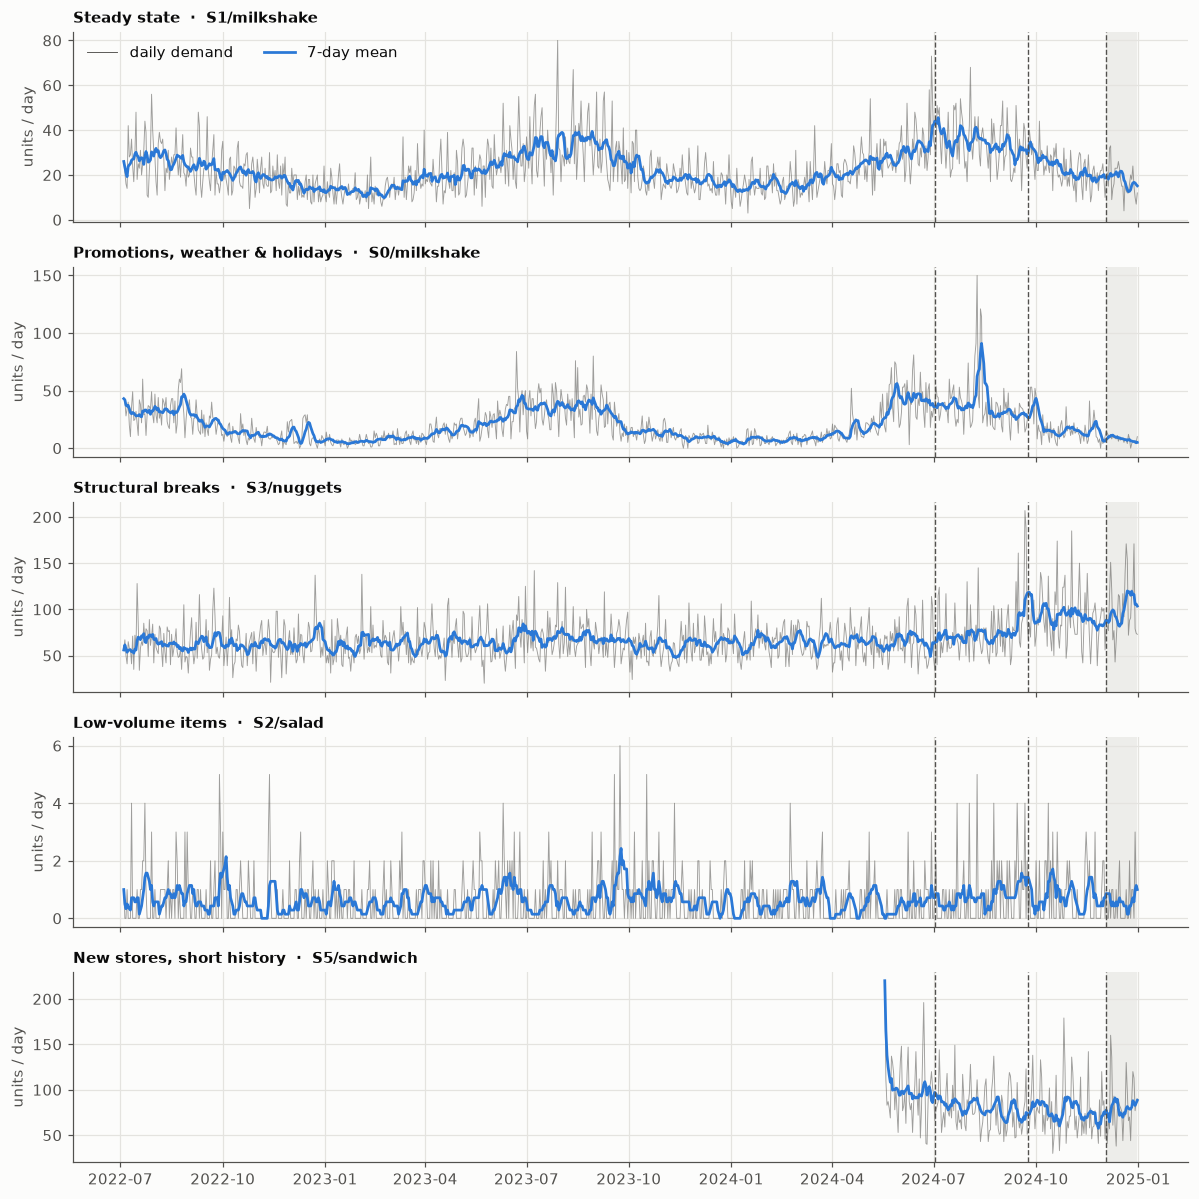

In [5]:
SHOWCASE = {"baseline": "S1/milkshake", "drivers": "S0/milkshake", "regime_shift": "S3/nuggets",
            "intermittent": "S2/salad", "cold_start": "S5/sandwich"}
fig, axes = plt.subplots(len(SCENARIOS), 1, figsize=(11, 11), sharex=True)
for ax, sc in zip(axes, SCENARIOS):
    uid = SHOWCASE[sc.name]
    g = DATA[sc.name].query("unique_id == @uid")
    ax.plot(g.ds, g.y, color=INK_2, lw=0.6, alpha=0.55)
    ax.plot(g.ds, g.y.rolling(7, min_periods=1).mean(), color=FAMILY_COLORS["Foundation"], lw=1.8)
    for o in ORIGINS:
        ax.axvline(o, color=INK_2, ls="--", lw=0.9)
    ax.axvspan(ORIGINS[-1], ORIGINS[-1] + pd.Timedelta(days=H), color=GRID, alpha=0.6, lw=0)
    ax.set_title(f"{sc.title}  ·  {uid}", fontsize=10)
    ax.set_ylabel("units / day")
axes[0].plot([], [], color=INK_2, lw=0.6, label="daily demand")
axes[0].plot([], [], color=FAMILY_COLORS["Foundation"], lw=1.8, label="7-day mean")
axes[0].legend(loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

The weekly rhythm differs by store type, so a new store's sibling of the same type carries
information about it. This is what the hierarchical model and the global models can exploit:

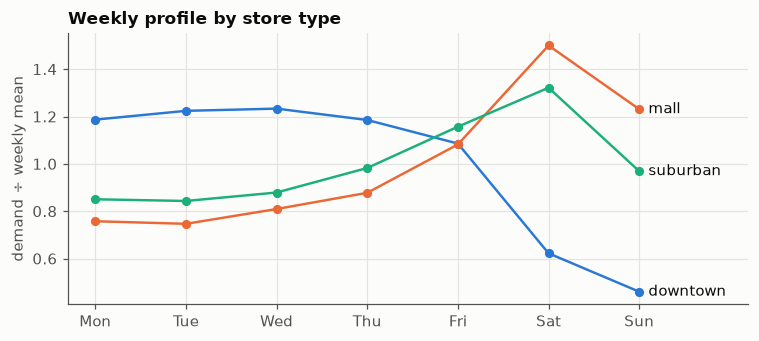

In [6]:
base = DATA["baseline"].assign(dow=lambda d: d.ds.dt.dayofweek)
profile = (base.groupby(["store_type", "dow"]).y.mean() / base.groupby("store_type").y.mean()).unstack(0)
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, (stype, col) in enumerate(profile.items()):
    color = list(FAMILY_COLORS.values())[k]
    ax.plot(range(7), col.values, marker="o", ms=5, color=color)
    ax.annotate(stype, (6, col.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlim(-0.3, 7.2)
ax.set_ylabel("demand ÷ weekly mean")
ax.set_title("Weekly profile by store type")
fig.tight_layout()
plt.show()

In the `drivers` scenario, promotions, heat and holiday closures move demand far beyond the
seasonal pattern:

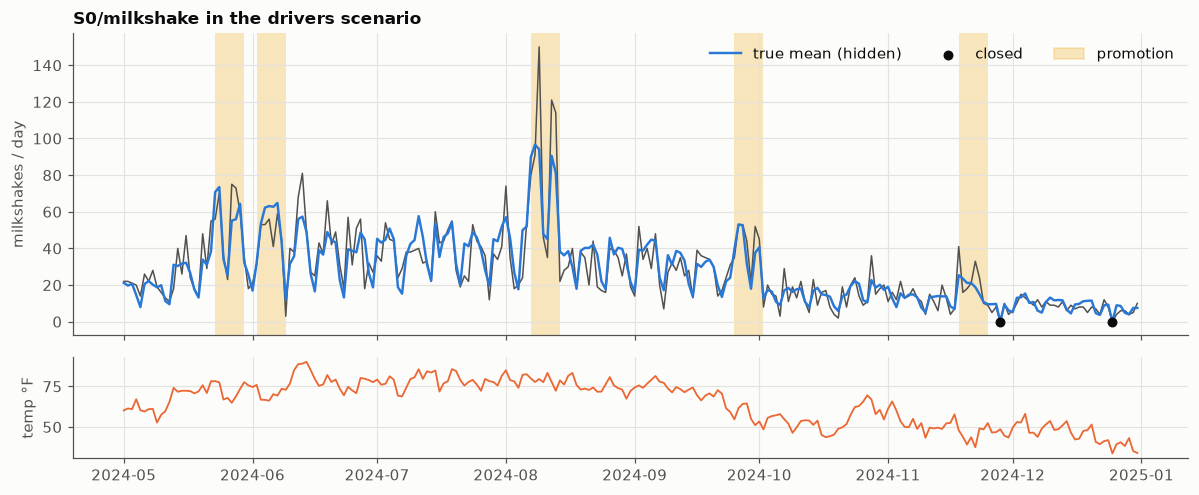

In [7]:
g = DATA["drivers"].query("unique_id == 'S0/milkshake' and ds >= '2024-05-01' and ds <= '2024-12-31'")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(g.ds, g.y, color=INK_2, lw=1)
ax.plot(g.ds, g.mu_true, color=FAMILY_COLORS["Foundation"], lw=1.6, label="true mean (hidden)")
for start, block in g[g.promo == 1].groupby((g.promo != g.promo.shift()).cumsum()[g.promo == 1]):
    ax.axvspan(block.ds.min(), block.ds.max() + pd.Timedelta(days=1), color=FAMILY_COLORS["Bayesian"], alpha=0.25, lw=0)
ax.scatter(g.ds[g.closed == 1], g.y[g.closed == 1], color=INK, s=30, zorder=3, label="closed")
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color=FAMILY_COLORS["Bayesian"], alpha=0.25, label="promotion"))
ax.legend(handles=handles, loc="upper right", ncol=3)
ax.set_ylabel("milkshakes / day")
ax.set_title("S0/milkshake in the drivers scenario")
ax2.plot(g.ds, g.temp, color=FAMILY_COLORS["Classical"], lw=1.2)
ax2.set_ylabel("temp °F")
fig.tight_layout()
plt.show()

## 2. Backtest protocol and metrics

For each scenario and each of the 3 forecast origins, every method sees data up to and
including the origin and forecasts the next **28 days** for all 30 series. Covariates
(`promo`, `temp`, `rain`, `closed`) are available for the forecast window, but only some
methods use them. Each method returns a point forecast and the 0.1, 0.2, …, 0.9 quantiles.

| Metric | Definition | Reads as |
|---|---|---|
| **WQL** | mean over quantiles of $2\sum \rho_q(y-\hat y_q) / \sum y$ | probabilistic accuracy (≈ CRPS); lower is better. Used in the Chronos/TimesFM papers |
| **WAPE** | $\sum\lvert y-\hat y\rvert / \sum y$ | volume-weighted point error |
| **MASE** | MAE ÷ in-sample MAE of the seasonal-naive forecast, averaged over series | scale-free point error; < 1 beats last-week's-weekday |
| **Cov80** | share of actuals inside the 10–90% band | calibration; should be ≈ 0.80 |
| **Bias** | $\sum(\hat y-y)/\sum y$ | systematic over- or under-forecast |

Quantile-producing methods use the median as their point forecast, while the statsforecast
models use the mean. WAPE favours the median, which matters most for intermittent demand.

In [8]:
def pinball(y, q_pred, q):
    diff = y - q_pred
    return np.maximum(q * diff, (q - 1) * diff)


def mase_scale(train: pd.DataFrame) -> pd.Series:
    """In-sample MAE of the weekly seasonal-naive forecast, per series."""
    t = train.sort_values(["unique_id", "ds"])
    err = (t.y - t.groupby("unique_id").y.shift(7)).abs()
    return err.groupby(t.unique_id).mean().clip(lower=1e-3)


def score(fc: pd.DataFrame) -> pd.Series:
    """`fc` holds forecasts joined with actuals (`y`) and the per-series MASE scale."""
    denom = fc.y.abs().sum()
    out = {
        "WAPE": (fc.point - fc.y).abs().sum() / denom,
        "MASE": ((fc.point - fc.y).abs() / fc.mase_scale).groupby([fc.unique_id, fc.origin]).mean().mean(),
        "Bias": (fc.point - fc.y).sum() / denom,
    }
    if fc[Q_COLS].notna().all().all():
        out["WQL"] = np.mean([2 * pinball(fc.y, fc[c], q).sum() / denom for c, q in zip(Q_COLS, QUANTILES)])
        out["Cov80"] = ((fc.y >= fc["q0.1"]) & (fc.y <= fc["q0.9"])).mean()
    else:
        out["WQL"] = out["Cov80"] = np.nan
    return pd.Series(out)


def finalize(fc: pd.DataFrame) -> pd.DataFrame:
    """Clip to non-negative and sort quantiles so they never cross."""
    fc = fc.copy()
    fc["point"] = fc.point.clip(lower=0)
    if fc[Q_COLS].notna().all().all():
        fc[Q_COLS] = np.sort(np.clip(fc[Q_COLS].to_numpy(), 0, None), axis=1)
    return fc[["unique_id", "ds", "point", *Q_COLS]]

## 3. The methods

Every method has the same signature, `forecast(train, future) -> DataFrame[unique_id, ds,
point, q0.1 … q0.9]`. `train` holds history up to the origin and `future` holds the
covariates for the next 28 days.

### 3a. Baseline and classical local models (statsforecast)
Each fits one model per series. `AutoETS` selects error/trend/season components by AICc
(seasonal exponential smoothing). `AutoARIMA` selects a seasonal ARIMA (AR + MA processes on
the weekly cycle). `MSTL` peels off weekly and yearly seasonality with STL, then forecasts the
remainder with ETS. `CrostonSBA` forecasts the size of non-zero demands and the interval
between them separately, and returns only a point forecast. Intervals for the other models
come from their Gaussian errors, converted to quantiles.

In [9]:
SF_LEVELS = [20, 40, 60, 80]


def _sf_forecast(model, train, future, n_jobs=1):
    sf = StatsForecast(models=[model], freq="D", n_jobs=n_jobs, fallback_model=SeasonalNaive(season_length=7))
    has_pi = not isinstance(model, CrostonSBA)
    out = sf.forecast(df=train[["unique_id", "ds", "y"]], h=H, level=SF_LEVELS if has_pi else None)
    name = repr(model)
    out = out.rename(columns={name: "point"})
    for lvl in SF_LEVELS:
        lo, hi = round(0.5 - lvl / 200, 1), round(0.5 + lvl / 200, 1)
        out[f"q{lo:.1f}"] = out.get(f"{name}-lo-{lvl}", np.nan)
        out[f"q{hi:.1f}"] = out.get(f"{name}-hi-{lvl}", np.nan)
    out["q0.5"] = out.point if has_pi else np.nan
    return finalize(out)


def fc_seasonal_naive(train, future):
    return _sf_forecast(SeasonalNaive(season_length=7), train, future)


def fc_autoets(train, future):
    return _sf_forecast(AutoETS(season_length=7), train, future)


def fc_autoarima(train, future):
    # The stepwise order search is the slow part, and a year is plenty for a weekly-seasonal ARIMA.
    recent = train[train.ds > train.ds.max() - pd.Timedelta(days=365)]
    return _sf_forecast(AutoARIMA(season_length=7), recent, future, n_jobs=-1)  # parallel over series


def fc_mstl(train, future):
    return _sf_forecast(MSTL(season_length=[7, 365]), train, future)


def fc_croston(train, future):
    return _sf_forecast(CrostonSBA(), train, future)

### 3b. Global ML model: LightGBM direct quantile regression

One model is trained across all 30 series. Each training example pairs what was known at an
origin $o$ with demand at day $o+k$, for $k = 1 \dots 28$. Building examples this way lets a
single model forecast every horizon directly, without recursion, and never peeks past the origin.

* **Origin features**, divided by the series' 28-day mean so stores of different sizes share
  patterns: last day, last 7-day mean, mean of the last 4 same-weekdays, last year's
  seasonal ratio for the target date, and the age of the series.
* **Target-day features**: horizon $k$, weekday, day-of-year, promo, post-promo, temperature,
  rain, closed. Item and store are categorical.
* One model per quantile (pinball loss), weighted by series scale so the loss tracks absolute units.

In [10]:
LGB_PARAMS = dict(learning_rate=0.07, n_estimators=200, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1)
PAD = 400  # NaN padding in front of the history so look-backs never go negative


def _post_promo(promo: np.ndarray) -> np.ndarray:
    post = np.zeros_like(promo)
    for lag in (1, 2, 3):
        post[..., lag:] = np.maximum(post[..., lag:], promo[..., :-lag])
    return post * (1 - promo)


def _wide(train, future, extra_covariates=()):
    """Pivot to (series × day) arrays with PAD NaN days in front."""
    full = pd.concat([train, future.assign(y=np.nan)], ignore_index=True)
    dates = pd.date_range(full.ds.min() - pd.Timedelta(days=PAD), full.ds.max(), freq="D")
    ids = sorted(full.unique_id.unique())

    def piv(col):
        return full.pivot(index="unique_id", columns="ds", values=col).reindex(index=ids, columns=dates).to_numpy(float)

    W = {c: piv(c) for c in ["y", *COVARIATES, *extra_covariates]}
    W["extra_covariates"] = list(extra_covariates)
    W["y_target"] = W["y"].copy()  # closed days stay 0 as targets...
    W["y"][W["closed"] == 1] = np.nan  # ...but are ignored as features
    W["promo"] = np.nan_to_num(W["promo"])
    W["post_promo"] = _post_promo(W["promo"])
    W["first_day"] = np.argmax(~np.isnan(W["y_target"]), axis=1)
    W["dates"], W["ids"] = dates, ids
    meta = full.drop_duplicates("unique_id").set_index("unique_id").loc[ids]
    W["item_code"] = pd.Categorical(meta["item"], categories=ITEMS.item).codes
    W["store_code"] = pd.Categorical(meta["store"], categories=STORES.store).codes
    return W


def _features(W, o):
    """Feature rows for all series at origin index `o`, horizons 1..H."""
    Y = W["y"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        scale = np.maximum(np.nanmean(Y[:, o - 27:o + 1], 1), 0.1)
        last7 = np.nanmean(Y[:, o - 6:o + 1], 1) / scale
        ly_base = np.nanmean(Y[:, o - 364 - 27:o - 364 + 1], 1)
        rows = []
        for k in range(1, H + 1):
            d = o + k
            d0 = d - 7 * int(np.ceil(k / 7))  # most recent same weekday at or before the origin
            date = W["dates"][d]
            rows.append(pd.DataFrame({
                "row": np.arange(len(scale)), "k": k, "scale": scale,
                "last1": Y[:, o] / scale, "last7": last7,
                "same_dow4": np.nanmean(Y[:, [d0, d0 - 7, d0 - 14, d0 - 21]], 1) / scale,
                "ly_ratio": np.nanmean(Y[:, d - 364 - 3:d - 364 + 4], 1) / ly_base,
                "age": o - W["first_day"],
                "dow": date.dayofweek, "doy_sin": np.sin(2 * np.pi * date.dayofyear / 365.25),
                "doy_cos": np.cos(2 * np.pi * date.dayofyear / 365.25),
                "promo": W["promo"][:, d], "post_promo": W["post_promo"][:, d],
                "temp": W["temp"][:, d], "rain": W["rain"][:, d], "closed": W["closed"][:, d],
                "item": W["item_code"], "store": W["store_code"],
                **{c: W[c][:, d] for c in W["extra_covariates"]},
                "target": W["y_target"][:, d] / scale, "d": d,
            }))
    return pd.concat(rows, ignore_index=True)


LGB_FEATURES = ["k", "last1", "last7", "same_dow4", "ly_ratio", "age", "dow", "doy_sin", "doy_cos",
                "promo", "post_promo", "temp", "rain", "closed", "item", "store"]


def fc_lightgbm(train, future, extra_covariates=None):
    extra_covariates = EXTRA_COVARIATES if extra_covariates is None else extra_covariates
    W = _wide(train, future, extra_covariates)
    features = LGB_FEATURES + list(extra_covariates)
    o_end = W["dates"].get_loc(train.ds.max())
    first = PAD + 28
    tr = pd.concat([_features(W, o) for o in range(first, o_end - 1, 5)], ignore_index=True)
    tr = tr[(tr.d <= o_end) & tr.target.notna() & (tr.age >= 14)]
    te = _features(W, o_end)
    preds = {}
    for q, col in zip(QUANTILES, Q_COLS):
        model = lgb.LGBMRegressor(objective="quantile", alpha=q, random_state=SEED, **LGB_PARAMS)
        model.fit(tr[features], tr.target, sample_weight=tr.scale, categorical_feature=["item", "store"])
        preds[col] = model.predict(te[features]) * te.scale.to_numpy()
    out = pd.DataFrame({"unique_id": np.array(W["ids"])[te.row], "ds": W["dates"][te.d], **preds})
    out["point"] = out["q0.5"]
    return finalize(out)

### 3c. Bayesian hierarchical model (PyMC + NUTS)

A negative-binomial GLM fit jointly to all 30 series. *Partial pooling* means every group
effect is drawn from a shared distribution, so groups with little data borrow strength from
the rest.

$$
\begin{aligned}
y_{j,d} &\sim \text{NegBin}(\mu_{j,d},\ \alpha_{\text{item}(j)}) \\
\log\mu_{j,d} &= L_{s,\,m(d)} + u_i + e_{s,i} + w_{s,\text{dow}} + v_{i,\text{dow}}
  + F_d^\top\gamma_{i} + X_{j,d}^\top\beta_{i}, \qquad s = \text{store}(j),\ i = \text{item}(j) \\
L_{s,m} &= L_{s,m-1} + \sigma_L\,\epsilon_{s,m},\ \ \epsilon \sim t_4 \quad\text{(store level: heavy-tailed random walk over 28-day segments } m\text{)}\\
u &\sim \text{ZeroSumNormal},\ \ e_{s,i} \sim \text{ZeroSumNormal}(\sigma_e) \quad\text{(item popularity, store × item deviations)}\\
w_{s,\cdot} &\sim \mathcal N(W_{\text{type}(s),\cdot},\ \sigma_w) \quad\text{(store weekday pattern pooled toward its store type)}\\
\gamma_i &\sim \mathcal N(\gamma_0, \sigma_\gamma),\ \ \beta_i \sim \mathcal N(\beta_0, 0.3) \quad\text{(yearly Fourier terms and covariate effects pooled across items)}
\end{aligned}
$$

$X$ = promo, post-promo, standardised temperature, rain. Closed days are structural zeros:
they are dropped from the likelihood and forecast as 0. The yearly pattern $\gamma_i$ is shared
by every store selling item $i$, which is how a 45-day-old store can still "know" that
milkshakes rise in summer. Its weekday pattern borrows from the other store of the same type.
The heavy-tailed random-walk level lets a store jump after a break while staying smooth
otherwise. The level of the last segment carries forward into the forecast.

Implementation notes, which matter more than they look:
* The first version used the textbook *non-centred* parameterisation everywhere and a
  linear trend plus changepoints. NUTS hit its maximum tree depth (~1,000 gradient steps per
  draw). With ~700 observations per series, effects that genuinely vary across groups (levels,
  item seasonality, item weekday shape) are strongly identified, which is exactly when the
  **centred** parameterisation mixes better.
* Effects whose group-level spread is ~0 (store deviations from their type's weekday pattern,
  store × item interactions) form funnels when centred, so those are **non-centred**. So is the
  random walk, whose step size is about as small as the noise in each 28-day level estimate.
  Covariate effects mix both cases (temperature matters a lot for milkshakes and not at all
  for nuggets, while rain hits everything equally), so they are pooled with a *fixed* scale.
  These choices, plus zero-sum constraints to remove redundant intercepts, cut sampling cost
  by about 10× and removed the divergences. On real data you would find them the same way,
  by reading the sampler diagnostics.
* Store levels and seasonal curves are computed on a (group × day) grid and then indexed,
  rather than with per-row products.
* We sample 4 chains with [nutpie](https://github.com/pymc-devs/nutpie), using a JAX-compiled gradient.

**Caveat for discussion.** This model is close to the true data-generating process because we
wrote both. It is *nearly well-specified*, which real data never allows, so read its results
as an upper bound on what careful structural modelling can achieve.

In [11]:
BAYES_HISTORY_DAYS = 728  # 26 segments of 28 days
SEGMENT = 28
N_FOURIER = 3
X_NAMES = ["promo", "post_promo", "temp_z", "rain"]
BAYES_DIAGNOSTICS = []  # sampler health per fit, shown in the results section


def _fourier(doy, K=N_FOURIER):
    w = 2 * np.pi * doy[:, None] * np.arange(1, K + 1)[None, :] / 365.25
    return np.hstack([np.sin(w), np.cos(w)])


def fc_bayes_hierarchical(train, future):
    full = pd.concat([train, future.assign(y=np.nan)], ignore_index=True).sort_values(["unique_id", "ds"])
    full["post_promo"] = full.groupby("unique_id").promo.transform(lambda p: _post_promo(p.to_numpy()))
    origin = train.ds.max()
    cal = pd.date_range(origin - pd.Timedelta(days=BAYES_HISTORY_DAYS - 1), origin + pd.Timedelta(days=H), freq="D")
    hist = full[(full.ds >= cal[0]) & (full.ds <= origin) & (full.closed == 0)]
    fut = full[full.ds > origin]

    stores, items, stypes = list(STORES.store), list(ITEMS.item), list(STORE_TYPE_DOW)
    idx = {"store": {s: k for k, s in enumerate(stores)}, "item": {s: k for k, s in enumerate(items)}}
    type_of_s = np.array([stypes.index(t) for t in STORES.store_type])
    n_seg = BAYES_HISTORY_DAYS // SEGMENT
    # Segment of each calendar day; the forecast window stays in the last (most recent) segment.
    seg_of_day = np.minimum(np.arange(len(cal)) // SEGMENT, n_seg - 1)
    F = _fourier(cal.dayofyear.to_numpy())

    def rows_to_arrays(rows):
        day = (rows.ds - cal[0]).dt.days.to_numpy()
        return {
            "sid": rows.store.map(idx["store"]).to_numpy(), "iid": rows.item.map(idx["item"]).to_numpy(),
            "day": day, "seg": seg_of_day[day], "dow": rows.ds.dt.dayofweek.to_numpy(),
            "X": np.column_stack([rows.promo, rows.post_promo, (rows.temp - 65) / 10, rows.rain, *[rows[c] for c in EXTRA_COVARIATES]]),
        }

    coords = {"store": stores, "item": items, "stype": stypes, "dow": range(7),
              "fourier": range(2 * N_FOURIER), "cov": X_NAMES + list(EXTRA_COVARIATES), "step": range(1, n_seg)}
    with pm.Model(coords=coords):
        D = {k: pm.Data(f"data_{k}", v) for k, v in rows_to_arrays(hist).items()}
        y_obs = pm.Data("y_obs", hist.y.to_numpy())

        level0 = pm.Normal("level0", np.log(hist.y.mean() + 0.5), 2.0, dims="store")
        steps = pm.HalfNormal("sig_level", 0.1) * pm.StudentT("z_level", nu=4, mu=0, sigma=1, dims=("store", "step"))
        level = level0[:, None] + pt.concatenate([pt.zeros((len(stores), 1)), pt.cumsum(steps, axis=1)], axis=1)  # (store, segment)
        u_item = pm.ZeroSumNormal("u_item", sigma=1.0, dims="item")
        e_store_item = pm.HalfNormal("sig_e", 0.3) * pm.ZeroSumNormal("z_e", sigma=1, dims=("store", "item"), n_zerosum_axes=2)

        w_type = pm.ZeroSumNormal("w_type", sigma=0.5, dims=("stype", "dow"))
        w_store = w_type[type_of_s] + pm.HalfNormal("sig_w_store", 0.1) * pm.ZeroSumNormal("z_w", sigma=1, dims=("store", "dow"))
        v_item = pm.ZeroSumNormal("v_item", sigma=pm.HalfNormal("sig_v_item", 0.2), dims=("item", "dow"))

        gamma = pm.Normal("gamma", mu=pm.Normal("g0", 0, 0.3, dims="fourier"), sigma=pm.HalfNormal("sig_g", 0.2), dims=("item", "fourier"))
        season = pm.math.dot(gamma, F.T)  # (item, day)
        beta = pm.Normal("beta", mu=pm.Normal("beta0", 0, 0.5, dims="cov"), sigma=0.3, dims=("item", "cov"))

        sid, iid, dow = D["sid"], D["iid"], D["dow"]
        log_mu = (level[sid, D["seg"]] + u_item[iid] + e_store_item[sid, iid] + w_store[sid, dow] + v_item[iid, dow]
                  + season[iid, D["day"]] + (D["X"] * beta[iid]).sum(-1))
        alpha = pm.LogNormal("alpha", np.log(10), 1.5, dims="item")
        pm.NegativeBinomial("y", mu=pm.math.exp(log_mu), alpha=alpha[iid], observed=y_obs, shape=sid.shape[0])

        idata = pm.sample(draws=250 if FAST else 300, tune=400 if FAST else 500, chains=4, nuts_sampler="nutpie",
                          random_seed=SEED, progressbar=False, compile_kwargs={"backend": "jax", "gradient_backend": "jax"})

        # Forecast: swap in the future rows and draw from the posterior predictive.
        open_fut = fut[fut.closed == 0]
        pm.set_data({**{f"data_{k}": v for k, v in rows_to_arrays(open_fut).items()}, "y_obs": np.zeros(len(open_fut))})
        ppc = pm.sample_posterior_predictive(idata, var_names=["y"], predictions=True, random_seed=SEED, progressbar=False)

    stats = idata["sample_stats"]
    BAYES_DIAGNOSTICS.append({"origin": origin, "divergences": int(stats["diverging"].sum()),
                              "mean_tree_depth": float(stats["depth"].mean()), "max_tree_depth": int(stats["depth"].max())})
    draws = ppc["predictions"]["y"].to_numpy().reshape(-1, len(open_fut))
    out = fut[["unique_id", "ds"]].copy()
    q = np.zeros((len(fut), len(QUANTILES)))
    q[(fut.closed == 0).to_numpy()] = np.quantile(draws, QUANTILES, axis=0).T
    out[Q_COLS] = q
    out["point"] = out["q0.5"]
    return finalize(out)

### 3d. Time-series foundation models (zero-shot)

These models were pretrained on large corpora of real and synthetic time series. Here they
are used **without any training on our data**: we pass the recent history as *context* and
they return quantile forecasts directly.

| Model | Size | Inputs we give it |
|---|---|---|
| **Chronos-Bolt (base)** (Amazon, 2024) | 205M | univariate history (patched T5 encoder-decoder, direct quantile head) |
| **TimesFM 2.5** (Google, 2025) | 200M | univariate history (decoder-only, patched) |
| **Chronos-2** (Amazon, 2025) | 120M | univariate history |
| **Chronos-2 + covariates** | | history plus past and future `promo`, `temp`, `rain`, `closed` |
| **Chronos-2 + cov + cross-learning** | | as above, and the 30 series attend to each other in one batch (in-context "pooling") |

TimesFM 3.0 is out, but its weights are licensed for non-commercial use only, so we use the
Apache-2.0 TimesFM 2.5. All models run on CPU. Loading the weights (a one-time download from
Hugging Face) is excluded from the timings. The wrappers are in `foundation_models.py`, shown
below. The cell runs them in a separate worker process for a technical reason explained in
the comment.

In [12]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

from IPython.display import Code

import foundation_models

# PyTorch and LightGBM each bundle an OpenMP runtime, and on macOS the two deadlock or segfault
# in one process. The foundation models therefore live in one long-lived worker process. Its
# initialiser loads all three models, so their download and initialisation stay out of the timings.
FM_POOL = ProcessPoolExecutor(max_workers=1, mp_context=mp.get_context("spawn"), initializer=foundation_models.warmup)


def _fm(name, train, future, **kwargs):
    fc = FM_POOL.submit(foundation_models.forecast, name, train, future, h=H, quantiles=QUANTILES, **kwargs).result()
    return finalize(fc)


def fc_chronos_bolt(train, future):
    return _fm("chronos_bolt", train, future)


def fc_timesfm(train, future):
    return _fm("timesfm", train, future)


def fc_chronos2(train, future):
    return _fm("chronos2", train, future)


def fc_chronos2_cov(train, future):
    return _fm("chronos2", train, future, covariates=COVARIATES + list(EXTRA_COVARIATES))


def fc_chronos2_cov_xl(train, future):
    return _fm("chronos2", train, future, covariates=COVARIATES + list(EXTRA_COVARIATES), cross_learning=True)


FM_POOL.submit(int).result()  # block until the worker has loaded the models
Code(filename="foundation_models.py", language="python")

"""Zero-shot time-series foundation-model forecasters.

These run in their own worker process (see the notebook): PyTorch and LightGBM each bundle an
OpenMP runtime, and on macOS the two deadlock or segfault when both are used in one process.

Every forecaster takes `train` (history up to the origin) and `future` (covariates for the next
`h` days) as long data frames keyed by `unique_id` and `ds`, and returns a frame with
`unique_id, ds, point, q0.1 … q0.9`.
"""

import logging
import os
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
for _name in ["transformers", "chronos", "huggingface_hub", "httpx"]:
    logging.getLogger(_name).setLevel(logging.ERROR)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
torch.set_num_threads(os.cpu_count())

DEVICE = "cpu"
_MODELS = {}


def load(name: str):
    """Load (once per process) and return a pretrained model."""
    if name not in _MODELS:
        if name == "chronos2":
            from chronos import Chronos2Pipeline

            _MODELS[name] = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
        elif name == "bolt":
            from chronos import BaseChronosPipeline

            _MODELS[name] = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-base", device_map=DEVICE)
        elif name == "timesfm":
            import timesfm

            model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
            model.compile(timesfm.ForecastConfig(
                max_context=1024, max_horizon=64, normalize_inputs=True, use_continuous_quantile_head=True,
                fix_quantile_crossing=True, infer_is_positive=True, per_core_batch_size=32,
            ))
            _MODELS[name] = model
    return _MODELS[name]


def warmup():
    """Process initialiser: load every model so download/initialisation stays out of the timings."""
    for name in ["chronos2", "bolt", "timesfm"]:
        load(name)


def _q_cols(quantiles):
    return [f"q{q:.1f}" for q in quantiles]


def _contexts(train):
    ids = sorted(train.unique_id.unique())
    return ids, [train.loc[train.unique_id == u].sort_values("ds").y.to_numpy(float) for u in ids]


def _frame(future, q, quantiles):
    """Attach a (series × horizon × quantile) array to the sorted future index."""
    out = future[["unique_id", "ds"]].sort_values(["unique_id", "ds"]).reset_index(drop=True)
    out[_q_cols(quantiles)] = q.reshape(-1, len(quantiles))
    out["point"] = out["q0.5"]
    return out


def chronos_bolt(train, future, h, quantiles):
    _, ctx = _contexts(train)
    ctx = [torch.tensor(c[-2048:], dtype=torch.float32) for c in ctx]
    q, _ = load("bolt").predict_quantiles(ctx, prediction_length=h, quantile_levels=list(quantiles))
    return _frame(future, q.numpy(), quantiles)


def timesfm_25(train, future, h, quantiles):
    _, ctx = _contexts(train)
    _, q = load("timesfm").forecast(horizon=h, inputs=ctx)  # q[..., 0] is the mean, then deciles 0.1..0.9
    return _frame(future, q[:, :h, 1:10], quantiles)


def chronos2(train, future, h, quantiles, covariates=(), cross_learning=False):
    cols = ["unique_id", "ds", *covariates]
    pred = load("chronos2").predict_df(
        train[[*cols, "y"]].sort_values(["unique_id", "ds"]),
        future_df=future[cols].sort_values(["unique_id", "ds"]) if covariates else None,
        prediction_length=h, quantile_levels=list(quantiles), id_column="unique_id", timestamp_column="ds",
        target="y", cross_learning=cross_learning, batch_size=256,
    )
    rename = {str(q): c for q, c in zip(quantiles, _q_cols(quantiles))} | {"predictions": "point"}
    return pred.rename(columns=rename)[["unique_id", "ds", "point", *_q_cols(quantiles)]]


FORECASTERS = {"chronos_bolt": chronos_bolt, "timesfm": timesfm_25, "chronos2": chronos2}


def forecast(name: str, train: pd.DataFrame, future: pd.DataFrame, **kwargs) -> pd.DataFrame:
    return FORECASTERS[name](t

### 3e. Oracle
The oracle knows the true mean $\mu$ (excluding the store-day shock, which nobody can foresee)
and the true noise model. Its quantiles come from Monte Carlo draws of shock + negative binomial.
It shows how much error is irreducible: the gap between a method and the oracle is the room
for improvement.

In [13]:
def make_oracle(sc: Scenario):
    def fc_oracle(train, future):
        rng = np.random.default_rng(SEED)
        mu = future.mu_true.to_numpy()[:, None] * np.exp(rng.normal(0, sc.shock_sd, (len(future), 4000)))
        draws = rng.negative_binomial(sc.dispersion, sc.dispersion / (sc.dispersion + mu + 1e-12))
        out = future[["unique_id", "ds"]].copy()
        out[Q_COLS] = np.quantile(draws, QUANTILES, axis=1).T
        out["point"] = out["q0.5"]
        return finalize(out)
    return fc_oracle

## 4. Run the backtest

Forecasts are cached per scenario under `results/`. Delete that folder, or set
`RECOMPUTE = True`, to re-run everything from scratch.

In [14]:
METHODS = {  # name -> (family, function)
    "Seasonal naive": ("Baseline", fc_seasonal_naive),
    "AutoETS": ("Classical", fc_autoets),
    "AutoARIMA": ("Classical", fc_autoarima),
    "MSTL": ("Classical", fc_mstl),
    "Croston-SBA": ("Classical", fc_croston),
    "LightGBM": ("ML", fc_lightgbm),
    "Bayes hierarchical": ("Bayesian", fc_bayes_hierarchical),
    "Chronos-Bolt": ("Foundation", fc_chronos_bolt),
    "TimesFM 2.5": ("Foundation", fc_timesfm),
    "Chronos-2": ("Foundation", fc_chronos2),
    "Chronos-2 +cov": ("Foundation", fc_chronos2_cov),
    "Chronos-2 +cov +XL": ("Foundation", fc_chronos2_cov_xl),
}
FAMILY = {m: f for m, (f, _) in METHODS.items()} | {"Oracle": "Reference", "Ensemble": "Ensemble"}
RECOMPUTE = False


def run_scenario(sc: Scenario) -> pd.DataFrame:
    global EXTRA_COVARIATES
    path = RESULTS_DIR / f"forecasts_{sc.name}.parquet"
    if path.exists() and not RECOMPUTE:
        return pd.read_parquet(path)
    EXTRA_COVARIATES = sc.extra_covariates
    try:
        return _run_scenario(sc, path)
    finally:
        EXTRA_COVARIATES = ()


def _run_scenario(sc: Scenario, path: Path) -> pd.DataFrame:
    df = DATA[sc.name]
    methods = {**{m: fn for m, (_, fn) in METHODS.items()}, "Oracle": make_oracle(sc)}
    frames = []
    for origin in ORIGINS:
        train = df[df.ds <= origin]
        test = df[(df.ds > origin) & (df.ds <= origin + pd.Timedelta(days=H))]
        test = test[test.unique_id.isin(train.unique_id.unique())]  # a store must be open to be forecast
        scale = mase_scale(train)
        visible_train = train.drop(columns="mu_true")
        future = test.drop(columns=["y"])  # the oracle needs mu_true, so the other methods drop it below
        for name, fn in methods.items():
            t0 = time.perf_counter()
            fc = fn(visible_train, future if name == "Oracle" else future.drop(columns="mu_true"))
            elapsed = time.perf_counter() - t0
            fc = fc.merge(test[["unique_id", "ds", "y", "store", "item", "segment"]], on=["unique_id", "ds"], how="inner")
            assert len(fc) == len(test), (name, len(fc), len(test))
            frames.append(fc.assign(method=name, origin=origin, seconds=elapsed, mase_scale=fc.unique_id.map(scale)))
            print(f"{sc.name:>12} | {origin.date()} | {name:<20} {elapsed:6.1f}s")
    out = pd.concat(frames, ignore_index=True)
    out.to_parquet(path)
    pd.DataFrame(BAYES_DIAGNOSTICS[-len(ORIGINS):]).to_parquet(RESULTS_DIR / f"bayes_diagnostics_{sc.name}.parquet")
    return out


FORECASTS = {sc.name: run_scenario(sc) for sc in SCENARIOS}

A simple **ensemble** is often the most robust choice in practice. We average the quantiles
(Vincentisation) of one classical, one ML and one foundation model: AutoETS + LightGBM + Chronos-2 +cov.

In [15]:
ENSEMBLE_OF = ["AutoETS", "LightGBM", "Chronos-2 +cov"]


def add_ensemble(fc: pd.DataFrame) -> pd.DataFrame:
    members = fc[fc.method.isin(ENSEMBLE_OF)]
    keys = ["unique_id", "ds", "origin"]
    ens = members.groupby(keys)[["point", *Q_COLS]].mean().reset_index()
    ens = ens.merge(members.drop_duplicates(keys)[[*keys, "y", "store", "item", "segment", "mase_scale"]], on=keys)
    per_origin = members.drop_duplicates(["method", "origin"]).groupby("origin").seconds.sum()
    ens["seconds"] = ens.origin.map(per_origin)
    return pd.concat([fc[fc.method != "Ensemble"], ens.assign(method="Ensemble")], ignore_index=True)


FORECASTS = {name: add_ensemble(fc) for name, fc in FORECASTS.items()}

## 5. Results

### 5a. Accuracy by scenario
Each cell shows a method's error divided by the seasonal-naive error in that scenario, so
**< 1 (blue) beats the baseline** and > 1 (red) is worse. The left panel is probabilistic
(WQL) and the right is point accuracy (WAPE). Croston-SBA produces no quantiles, so its
WQL cells are blank.

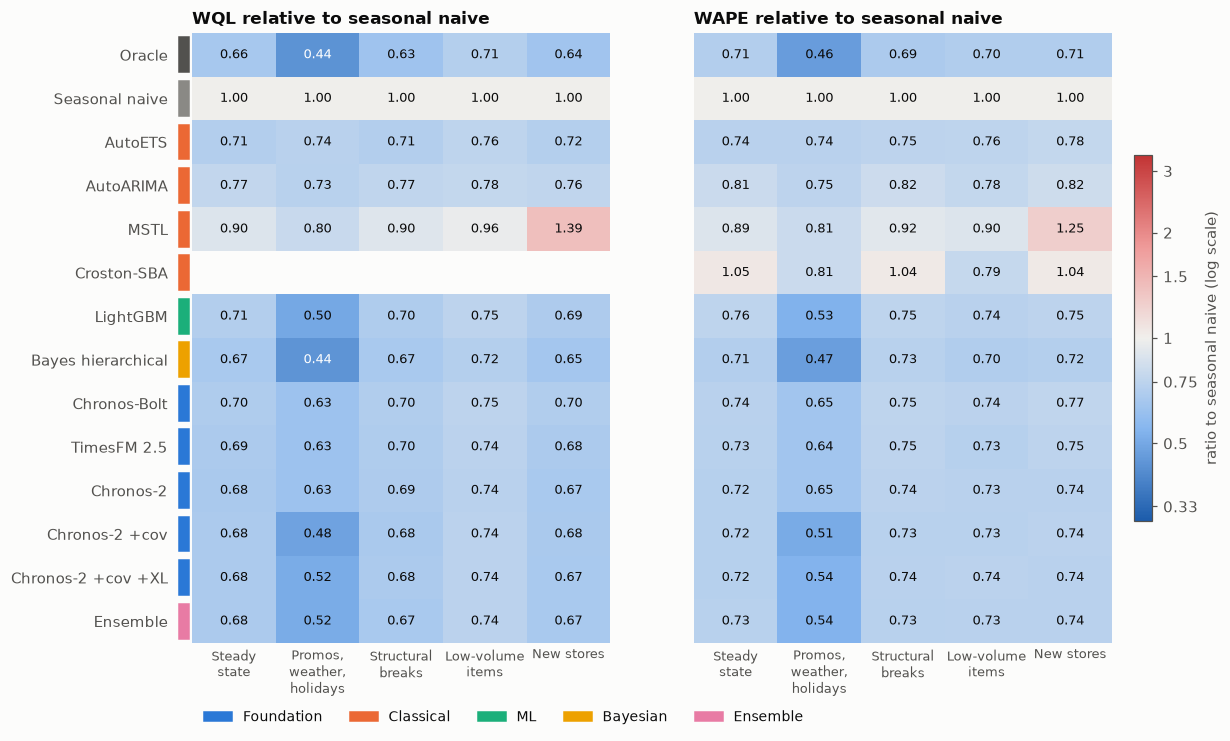

In [16]:
METHOD_ORDER = ["Oracle", *METHODS, "Ensemble"]


def summarize(fc: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for m, g in fc.groupby("method"):
        s = score(g)
        s["sec_per_origin"] = g.drop_duplicates("origin").seconds.mean()
        rows[m] = s
    return pd.DataFrame(rows).T.reindex([m for m in METHOD_ORDER if m in rows])


from matplotlib.colors import LinearSegmentedColormap, LogNorm

DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#c23434"])
SHORT_TITLES = {"baseline": "Steady\nstate", "drivers": "Promos,\nweather,\nholidays", "regime_shift": "Structural\nbreaks",
                "intermittent": "Low-volume\nitems", "cold_start": "New stores",
                "seasonal_cold_start": "New store before\na seasonal swing", "annual_calendar": "Academic calendar\n& annual events",
                "nonlinear_drivers": "Interacting\ndrivers"}


def relative_to_naive(summary):
    return summary[["WQL", "WAPE"]].div(summary.xs("Seasonal naive", level="method")[["WQL", "WAPE"]], level="scenario")


def plot_relative_heatmap(summary, method_order=None):
    method_order = method_order or METHOD_ORDER
    names = list(dict.fromkeys(summary.index.get_level_values("scenario")))
    rel = relative_to_naive(summary)
    fig, axes = plt.subplots(1, 2, figsize=(4 + 1.8 * len(names), 7.2), sharey=True)
    for ax, metric in zip(axes, ["WQL", "WAPE"]):
        M = rel[metric].unstack("scenario").reindex(index=method_order, columns=names)
        im = ax.imshow(M.to_numpy(float), cmap=DIVERGING, norm=LogNorm(vmin=0.3, vmax=1 / 0.3), aspect="auto")
        for (r, c), v in np.ndenumerate(M.to_numpy(float)):
            if np.isfinite(v):
                ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                        color="white" if (v < 0.45 or v > 2.2) else INK)
        ax.set_xticks(range(M.shape[1]), [SHORT_TITLES[n] for n in names], fontsize=8.5)
        ax.set_yticks(range(M.shape[0]), M.index)
        ax.tick_params(length=0)
        ax.tick_params(axis="y", pad=16)  # room for the family swatches
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(f"{metric} relative to seasonal naive")
    # Family swatches beside the method names (labels stay in ink).
    for r, m in enumerate(method_order):
        axes[0].add_patch(plt.Rectangle((-0.66, r - 0.4), 0.12, 0.8, color=FAMILY_COLORS[FAMILY[m]], clip_on=False))
    axes[0].legend(handles=[Patch(color=FAMILY_COLORS[f], label=f) for f in ["Foundation", "Classical", "ML", "Bayesian", "Ensemble"]],
                   loc="upper left", bbox_to_anchor=(0, -0.09 - 0.02 * (len(names) < 4)), ncol=5 if len(names) > 3 else 3, fontsize=9)
    cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02, ticks=[0.33, 0.5, 0.75, 1, 1.5, 2, 3])
    cb.ax.minorticks_off()
    cb.ax.set_yticklabels(["0.33", "0.5", "0.75", "1", "1.5", "2", "3"])
    cb.set_label("ratio to seasonal naive (log scale)", color=INK_2)
    plt.show()


SUMMARY = pd.concat({name: summarize(fc) for name, fc in FORECASTS.items()}, names=["scenario", "method"])
rel = relative_to_naive(SUMMARY)
plot_relative_heatmap(SUMMARY)

Absolute numbers for reference (WQL, WAPE and MASE: lower is better; Cov80 should be ≈ 0.80):

In [17]:
with pd.option_context("display.float_format", "{:.3f}".format, "display.max_columns", 50, "display.width", 250):
    for metric in ["WQL", "WAPE", "MASE", "Cov80", "Bias"]:
        print(f"\n{metric}")
        display(SUMMARY[metric].unstack("scenario").reindex(index=METHOD_ORDER, columns=list(FORECASTS)).round(3))


WQL


scenario,baseline,drivers,regime_shift,intermittent,cold_start
method,,,,,
Oracle,0.155,0.157,0.152,0.612,0.156
Seasonal naive,0.234,0.361,0.240,0.858,0.243
AutoETS,0.165,0.267,0.170,0.652,0.174
AutoARIMA,0.180,0.264,0.184,0.669,0.186
MSTL,0.210,0.288,0.217,0.827,0.339
Croston-SBA,NaN,NaN,NaN,NaN,NaN
LightGBM,0.165,0.182,0.167,0.645,0.167
Bayes hierarchical,0.156,0.159,0.161,0.614,0.158
Chronos-Bolt,0.163,0.228,0.168,0.643,0.171



WAPE


scenario,baseline,drivers,regime_shift,intermittent,cold_start
method,,,,,
Oracle,0.201,0.203,0.196,0.792,0.202
Seasonal naive,0.285,0.439,0.286,1.127,0.286
AutoETS,0.210,0.324,0.216,0.855,0.223
AutoARIMA,0.231,0.329,0.235,0.879,0.236
MSTL,0.254,0.355,0.264,1.013,0.359
Croston-SBA,0.299,0.354,0.298,0.885,0.299
LightGBM,0.215,0.234,0.216,0.833,0.215
Bayes hierarchical,0.203,0.205,0.208,0.794,0.205
Chronos-Bolt,0.209,0.284,0.216,0.835,0.220



MASE


scenario,baseline,drivers,regime_shift,intermittent,cold_start
method,,,,,
Oracle,0.751,0.599,0.717,0.758,0.692
Seasonal naive,1.073,1.206,1.037,1.061,0.992
AutoETS,0.791,0.916,0.789,0.834,0.764
AutoARIMA,0.882,0.950,0.865,0.854,0.820
MSTL,0.951,1.009,0.966,0.975,1.166
Croston-SBA,1.081,1.019,1.058,0.857,0.986
LightGBM,0.801,0.685,0.781,0.797,0.737
Bayes hierarchical,0.755,0.606,0.759,0.761,0.702
Chronos-Bolt,0.780,0.822,0.786,0.801,0.744



Cov80


scenario,baseline,drivers,regime_shift,intermittent,cold_start
method,,,,,
Oracle,0.809,0.804,0.827,0.934,0.816
Seasonal naive,0.913,0.881,0.917,0.914,0.925
AutoETS,0.813,0.843,0.793,0.869,0.774
AutoARIMA,0.804,0.837,0.809,0.885,0.828
MSTL,0.519,0.702,0.530,0.562,0.259
Croston-SBA,NaN,NaN,NaN,NaN,NaN
LightGBM,0.764,0.728,0.754,0.840,0.751
Bayes hierarchical,0.812,0.800,0.801,0.924,0.814
Chronos-Bolt,0.802,0.799,0.813,0.782,0.833



Bias


scenario,baseline,drivers,regime_shift,intermittent,cold_start
method,,,,,
Oracle,-0.030,-0.028,-0.024,-0.358,-0.021
Seasonal naive,0.004,-0.011,-0.003,-0.013,0.017
AutoETS,0.002,0.016,0.009,-0.038,0.023
AutoARIMA,0.006,-0.001,0.017,-0.019,-0.009
MSTL,-0.011,-0.041,-0.000,-0.001,0.178
Croston-SBA,-0.049,-0.040,-0.051,-0.060,-0.037
LightGBM,0.001,-0.014,-0.036,-0.385,-0.019
Bayes hierarchical,-0.041,-0.038,-0.028,-0.420,-0.002
Chronos-Bolt,-0.042,-0.097,-0.040,-0.465,0.010


### 5b. Overall ranking and cost
For each method: the average rank by WQL across the five scenarios (oracle excluded), and the
wall-clock time to fit and forecast all 30 series at one origin. Local models are fit once per
series and the foundation models only run inference. The y-axis is the geometric mean of the
relative WQL across scenarios.

,mean WQL rank,geo-mean WQL vs naive,sec / origin,family
method,,,,
Bayes hierarchical,1.0,0.621,86.575,Bayesian
Chronos-2,3.6,0.680,0.380,Foundation
Chronos-2 +cov,3.6,0.646,1.778,Foundation
Chronos-2 +cov +XL,4.0,0.654,1.643,Foundation
Ensemble,4.0,0.653,34.804,Ensemble
TimesFM 2.5,5.8,0.686,1.247,Foundation
LightGBM,6.6,0.663,27.041,ML
Chronos-Bolt,7.6,0.696,0.317,Foundation
AutoETS,9.0,0.725,5.984,Classical


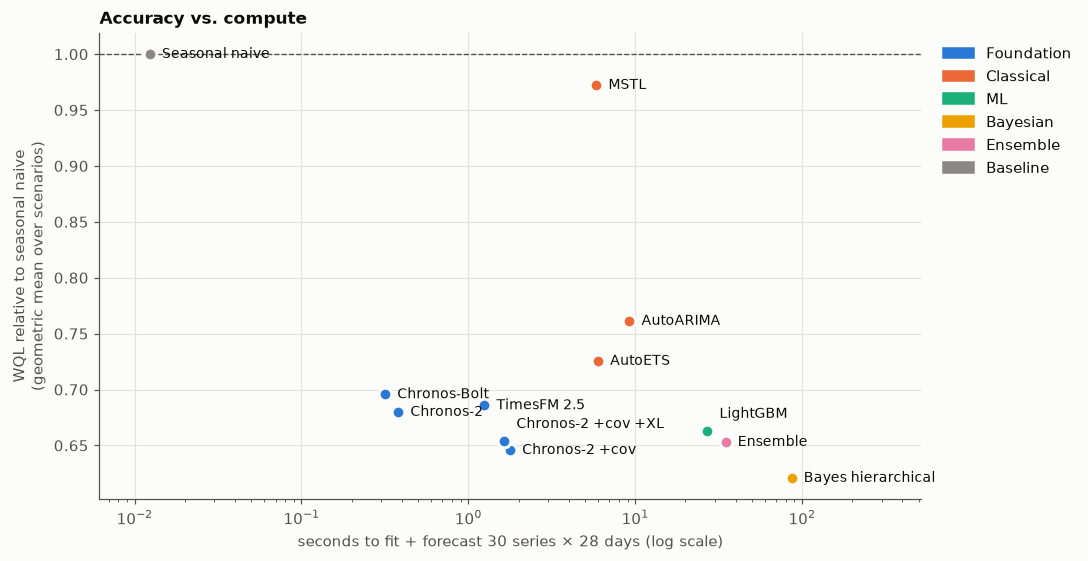

In [18]:
wql = SUMMARY["WQL"].unstack("scenario").drop(index="Oracle")
ranks = wql.rank(axis=0)
overall = pd.DataFrame({
    "mean WQL rank": ranks.mean(1),
    "geo-mean WQL vs naive": np.exp(np.log(rel["WQL"].unstack("scenario").drop(index="Oracle")).mean(1)),
    "sec / origin": SUMMARY["sec_per_origin"].unstack("scenario").drop(index="Oracle").mean(1),
    "family": [FAMILY[m] for m in wql.index],
}).dropna(subset=["mean WQL rank"]).sort_values("mean WQL rank")
display(overall.round(3))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.set_xscale("log")
for m, r in overall.iterrows():
    ax.scatter(r["sec / origin"], r["geo-mean WQL vs naive"], s=70, color=FAMILY_COLORS[r.family], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_xlim(overall["sec / origin"].min() / 2, overall["sec / origin"].max() * 6)
fig.canvas.draw()
placed = []  # nudge labels vertically until they stop overlapping
for m, r in overall.sort_values("geo-mean WQL vs naive").iterrows():
    for dy in [0, -11, 11, -22, 22, -33, 33]:
        t = ax.annotate(m, (r["sec / origin"], r["geo-mean WQL vs naive"]), xytext=(8, dy), textcoords="offset points",
                        va="center", fontsize=9, color=INK)
        bb = t.get_window_extent(fig.canvas.get_renderer()).expanded(1.02, 1.15)
        if not any(bb.overlaps(p) for p in placed):
            placed.append(bb)
            break
        t.remove()
ax.axhline(1, color=INK_2, lw=0.9, ls="--")
ax.set_xlabel("seconds to fit + forecast 30 series × 28 days (log scale)")
ax.set_ylabel("WQL relative to seasonal naive\n(geometric mean over scenarios)")
ax.set_title("Accuracy vs. compute")
ax.legend(handles=[Patch(color=FAMILY_COLORS[f], label=f) for f in ["Foundation", "Classical", "ML", "Bayesian", "Ensemble", "Baseline"]],
          loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

### 5c. Where the scenarios bite: affected vs. unaffected stores
In `cold_start`, compare the three **new stores** with the three established ones. In
`regime_shift`, compare the three **shifted stores** with the stable ones. Each dot is WQL
relative to seasonal naive *on that segment*, so the baseline sits at 1 by construction.

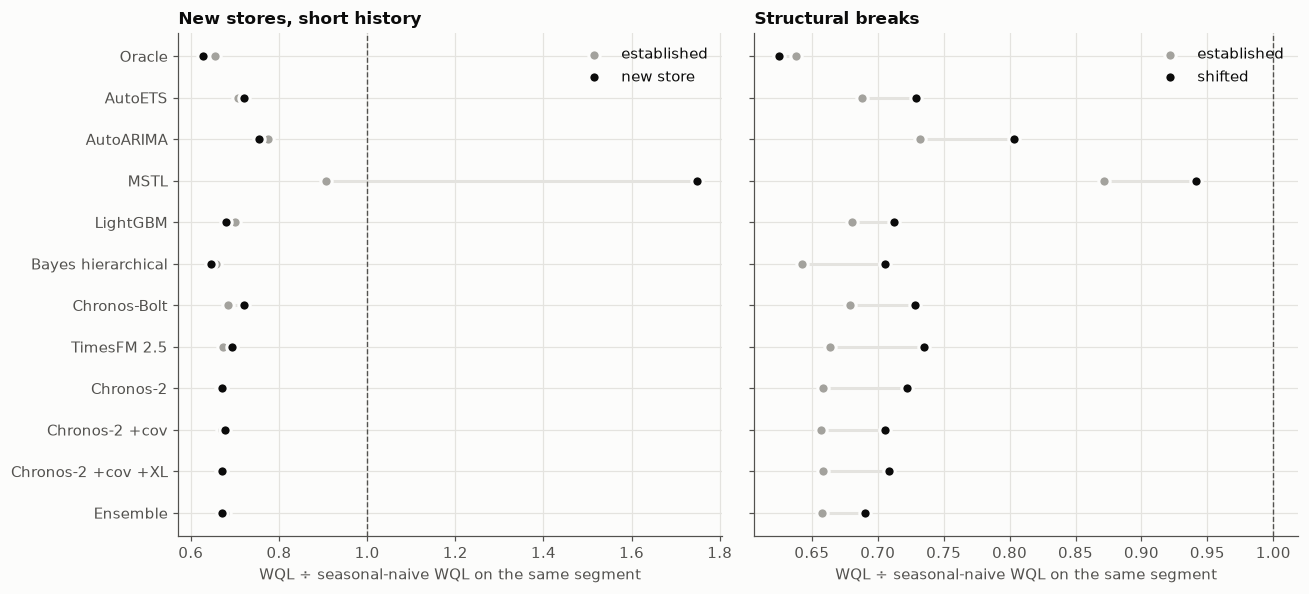

In [19]:
def plot_segments(forecasts, names):
    """WQL relative to seasonal naive on the affected vs. unaffected stores of each scenario."""
    rows = []
    for name in names:
        for (m, segment), g in forecasts[name].groupby(["method", "segment"]):
            rows.append({"scenario": name, "method": m, "segment": segment, "WQL": score(g)["WQL"]})
    seg = pd.DataFrame(rows)
    naive = seg[seg.method == "Seasonal naive"].set_index(["scenario", "segment"]).WQL
    seg["rel"] = seg.WQL / naive.reindex(pd.MultiIndex.from_frame(seg[["scenario", "segment"]])).to_numpy()
    seg = seg.dropna()
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 5.5), sharey=True, squeeze=False)
    order = [m for m in METHOD_ORDER if m in seg.method.unique() and m != "Seasonal naive"][::-1]
    for ax, name in zip(axes[0], names):
        d = seg[seg.scenario == name]
        segments = sorted(d.segment.unique(), key=lambda x: x != "established")  # established first, drawn light
        for segment, color in zip(segments, ["#a3a29d", INK]):
            dd = d[d.segment == segment].set_index("method").reindex(order)
            ax.scatter(dd.rel, range(len(order)), color=color, s=55, edgecolor=SURFACE, linewidth=2, zorder=3, label=segment)
        wide = d.pivot(index="method", columns="segment", values="rel").reindex(order)
        ax.hlines(range(len(order)), wide.min(1), wide.max(1), color=GRID, lw=2, zorder=2)
        ax.axvline(1, color=INK_2, lw=0.9, ls="--")
        ax.set_yticks(range(len(order)), order)
        ax.set_xlabel("WQL ÷ seasonal-naive WQL on the same segment")
        ax.set_title(SCENARIO_BY_NAME[name].title)
        ax.legend(loc="upper right")
    fig.tight_layout()
    plt.show()
    return seg


plot_segments(FORECASTS, ["cold_start", "regime_shift"]);

### 5d. Calibration
Share of actuals that fall inside each method's 10–90% band. Well-calibrated methods sit
near **0.80**. Lower means the intervals are too narrow (over-confident).

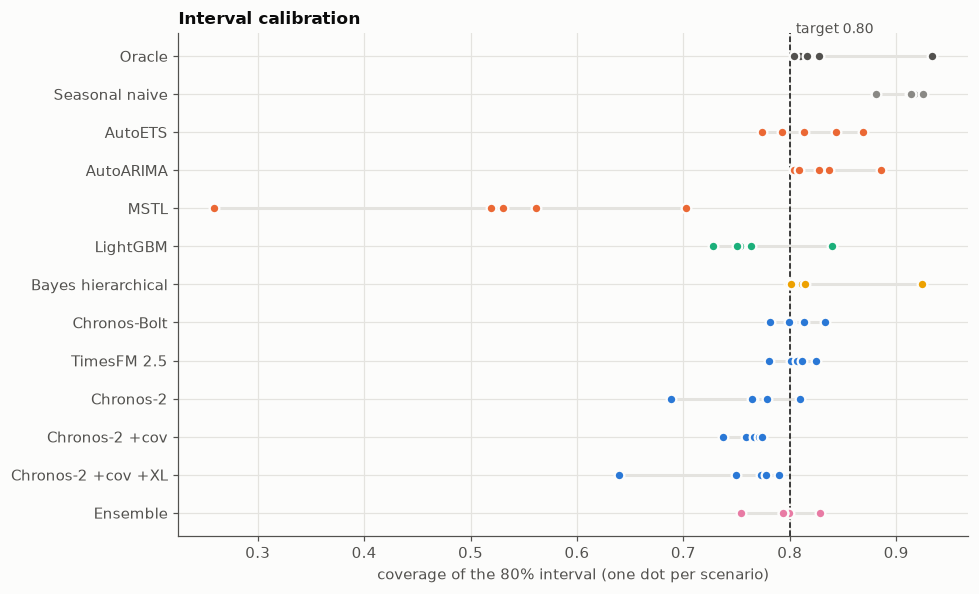

In [20]:
cov = SUMMARY["Cov80"].unstack("scenario").reindex(index=METHOD_ORDER, columns=list(FORECASTS)).dropna(how="all")
fig, ax = plt.subplots(figsize=(9, 5.5))
scen_list = list(FORECASTS)
for r, (m, row) in enumerate(cov.iloc[::-1].iterrows()):
    ax.hlines(r, row.min(), row.max(), color=GRID, lw=2, zorder=1)
    ax.scatter(row.to_numpy(), [r] * len(row), s=40, color=FAMILY_COLORS.get(FAMILY[m], INK_2), edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axvline(0.8, color=INK, lw=1, ls="--")
ax.annotate("target 0.80", (0.8, len(cov) - 0.4), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK_2)
ax.set_yticks(range(len(cov)), cov.index[::-1])
ax.set_xlabel("coverage of the 80% interval (one dot per scenario)")
ax.set_title("Interval calibration")
fig.tight_layout()
plt.show()

### 5e. What the forecasts look like
Three hard cases, each forecast by four representative methods: the holiday window in
`drivers`, a store hit by a competitor 10 days before the origin, and the youngest new store
at the first origin. The line is the median and the band is the 10–90% interval. Gray is history and
black is what actually happened.

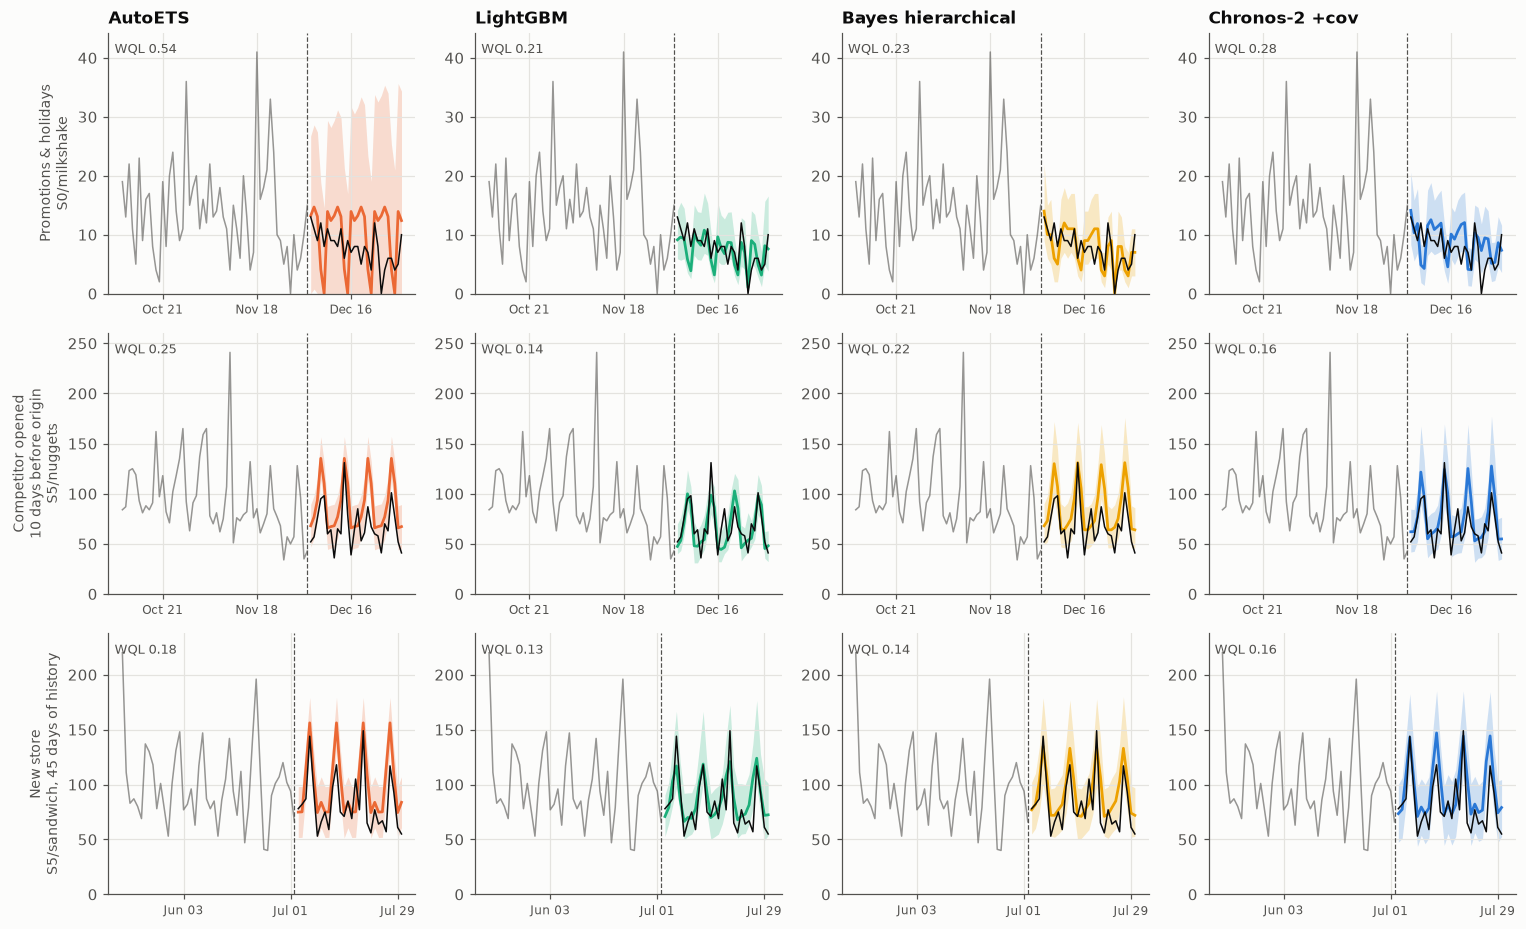

In [21]:
import matplotlib.dates as mdates

def plot_cases(forecasts, cases, show):
    """Rows = (scenario, series, origin, label); columns = methods. Gray = history, black = actual."""
    fig, axes = plt.subplots(len(cases), len(show), figsize=(3.5 * len(show), 2.85 * len(cases)), squeeze=False)
    for r, (name, uid, origin, label) in enumerate(cases):
        window_start = origin - pd.Timedelta(days=56)
        hist = DATA[name].query("unique_id == @uid and ds <= @origin and ds > @window_start")
        age = (origin - DATA[name].query("unique_id == @uid").ds.min()).days
        label = f"{label}\n{uid}, {age} days of history" if age < 365 else f"{label}\n{uid}"
        fc_all = forecasts[name].query("unique_id == @uid and origin == @origin")
        ymax = max(hist.y.max(), fc_all.y.max(), fc_all[fc_all.method.isin(show)]["q0.9"].max()) * 1.08
        for c, m in enumerate(show):
            ax = axes[r, c]
            f = fc_all[fc_all.method == m].sort_values("ds")
            color = FAMILY_COLORS[FAMILY[m]]
            ax.plot(hist.ds, hist.y, color=INK_2, lw=1, alpha=0.6)
            ax.fill_between(f.ds, f["q0.1"], f["q0.9"], color=color, alpha=0.22, lw=0)
            ax.plot(f.ds, f.point, color=color, lw=1.8)
            ax.plot(f.ds, f.y, color=INK, lw=1)
            ax.axvline(origin, color=INK_2, ls="--", lw=0.8)
            ax.set_ylim(0, ymax)
            ax.text(0.02, 0.96, f"WQL {score(f)['WQL']:.2f}", transform=ax.transAxes, va="top", fontsize=8.5, color=INK_2)
            if r == 0:
                ax.set_title(m, color=INK)
            if c == 0:
                ax.set_ylabel(label, fontsize=9)
            ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=4))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
            ax.tick_params(axis="x", labelsize=8)
    fig.tight_layout()
    plt.show()


plot_cases(FORECASTS, [("drivers", "S0/milkshake", ORIGINS[-1], "Promotions & holidays"),
                       ("regime_shift", "S5/nuggets", ORIGINS[-1], "Competitor opened\n10 days before origin"),
                       ("cold_start", "S5/sandwich", ORIGINS[0], "New store")],
           show=["AutoETS", "LightGBM", "Bayes hierarchical", "Chronos-2 +cov"])

### 5f. Bayesian sampler health
Divergences > 0 would mean the posterior geometry was not fully explored, and the forecasts
from that fit should be treated with suspicion.

In [22]:
diag = pd.concat({n: pd.read_parquet(RESULTS_DIR / f"bayes_diagnostics_{n}.parquet") for n in FORECASTS}, names=["scenario", "_"])
display(diag.reset_index(level="_", drop=True))

,origin,divergences,mean_tree_depth,max_tree_depth
scenario,,,,
baseline,2024-07-02,0,5.015000,6
baseline,2024-09-24,0,5.055000,6
baseline,2024-12-03,0,5.138333,7
drivers,2024-07-02,0,5.093333,7
drivers,2024-09-24,0,5.360833,7
drivers,2024-12-03,0,5.034167,7
regime_shift,2024-07-02,0,5.088333,6
regime_shift,2024-09-24,0,5.590000,7
regime_shift,2024-12-03,0,5.973333,8


## 6. Discussion

*The numbers below are from the cached full run: 5 scenarios × 3 origins × 30 series × 28 days.
WQL is quoted with the oracle (the noise floor) in brackets.*

### What we found

**1. On clean data, zero-shot foundation models are excellent.** In `baseline`, Chronos-2 (0.159),
TimesFM 2.5 (0.160) and Chronos-Bolt (0.163) all beat AutoETS (0.165), AutoARIMA (0.180) and MSTL
(0.210) without seeing a single training example [oracle 0.155]. They land within 3% of the noise
floor in under a second for all 30 series.

**2. Covariates are where the gap opens up, and Chronos-2 can use them in-context.** In `drivers`,
every univariate method stalls: TSFMs reach ≈0.227 and ETS/ARIMA ≈0.265. Models that see the
promo calendar, weather and closures do much better: Chronos-2 +cov 0.175, LightGBM 0.182, and the
Bayesian model 0.159 [0.157]. Chronos-2's zero-shot covariate handling recovers most of what a
purpose-built LightGBM feature pipeline gets, though it remains ~10% above the floor.

**3. The Bayesian hierarchical model ranks first in every scenario, with a big asterisk.** It is
nearly the true data-generating process (same link function, likelihood, seasonal form and
covariate effects), so it sits on the oracle almost everywhere. Its one visible weakness is the
one we built in by accident. The level is piecewise-constant over 28-day segments, so a break 10
days before the origin is averaged with pre-break days, and the forecast stays too high (see the
middle row of §5e). Structural assumptions pay off handsomely when right and cost you when they
are not, which matters more on real data where they never are exactly right. It is also
~50–250× slower than the TSFMs and needed real work to sample well (§3c notes).

**4. Structural breaks:** on the *shifted* stores, LightGBM, Chronos-2 +cov, the Bayesian model
and the ensemble cluster together (≈0.69–0.71 of naive), with AutoETS and TimesFM slightly behind
and AutoARIMA (fit on a year of history) clearly worst among the sensible methods. Methods that
weight recent data heavily adapt fastest.

**5. Cold start was less of a problem than expected.** Even the youngest store had 45 days of
history at the first origin. For a 28-day horizon the weekly pattern dominates and can be learnt
from six weeks, so most methods did about as well on new stores as on established ones. Pooling
still shows: on the new stores the Bayesian model (0.645 of naive) beats every other method
(0.67–0.72). Cross-learning helped Chronos-2 only slightly (0.670 vs. 0.679 with covariates
alone), and Chronos-Bolt struggled most with the short contexts. The clear failure is **MSTL** (1.4×
*worse* than naive, 80% intervals covering only 26%): its decomposition misbehaves on short series
with a fast-decaying opening "honeymoon".

**6. Intermittent demand:** everyone is close together (0.635–0.65) except MSTL and the naive
baseline, with the count-aware Bayesian model on the floor (0.614 [0.612]). Chronos-2's intervals
are *too narrow* on these low counts (Cov80 0.69, or 0.64 with cross-learning), while Chronos-Bolt
and TimesFM are better calibrated. Every median-based forecast shows large negative "bias" here,
the oracle included. That is expected for skewed counts, where the median sits below the mean.

**7. Calibration and robustness.** Chronos-Bolt, TimesFM and AutoETS/ARIMA have honest 80%
intervals; Chronos-2 and LightGBM run slightly narrow (0.73–0.78). The simple **ensemble**
(AutoETS + LightGBM + Chronos-2 +cov) never wins a scenario but is never far off. It is also the
best-calibrated non-oracle method, which is the usual argument for ensembles in production.

### Caveats
* **We wrote the simulator.** Every method is tested on demand generated by assumptions we chose,
  and the Bayesian model encodes most of them. Real data has misspecification, data errors,
  censored demand (stock-outs) and unknown drivers.
* **Perfect covariates.** Weather is given as realised values. With real forecasts the
  covariate-aware methods lose some of their edge in `drivers`.
* **Small experiment.** 30 series × 3 origins. Differences of 1–2% in WQL between neighbouring
  methods are within noise; only the large gaps (covariates vs. none, MSTL vs. the rest) are robust.
* **No tuning.** LightGBM hyperparameters, ETS/ARIMA search spaces and TSFM context lengths are
  defaults or close to them, and no TSFM was fine-tuned. Each could improve with effort, which is
  itself part of the comparison: the TSFMs were the least effort.

### Questions for discussion
1. Chronos-2 +cov got within ~10% of a hand-built LightGBM pipeline with zero feature
   engineering. When is "good enough with no pipeline" the right trade?
2. Where would *you* expect TSFMs to fail on real restaurant data? Think about new menu items,
   price changes and stock-outs.
3. The Bayesian model's strength and its weakness both come from its structure. How would you
   detect misspecification like the 28-day level segments without knowing the truth?
4. Cold start turned out easy because 45 days covers the dominant (weekly) cycle. What horizon
   or history length would make it hard again, and would cross-learning help then?
5. What would a fair test of fine-tuned TSFMs, or a TSFM + LightGBM stack, look like?

## 7. Stress tests: data designed to trip up the foundation models

Sections 1–6 were broadly kind to the foundation models. Here we deliberately build data that
exploits what a zero-shot TSFM *cannot* see. With covariates or cross-learning switched off,
Chronos and TimesFM forecast one series from its own recent values alone:

* **They are date-blind.** They see a sequence of numbers, not a calendar. A holiday or a school
  break has to be recognised from the shape of the history, or passed in as a covariate.
* **They see one series at a time.** Unless cross-learning is on, they cannot know that the
  store across town always doubles its milkshake sales in July.
* **They learn covariate effects in-context**, from one series' history. Effects that only show
  up in rare combinations (a threshold, an interaction) leave few examples to learn from.

Each scenario below targets one of these gaps. The hypotheses were written down **before** the
run:

| Scenario | What the data does | Why TSFMs should struggle | Who should win |
|---|---|---|---|
| `seasonal_cold_start` | A new store opens 41 days before each origin, just before the summer peak, the autumn drop and the December rush. Seasonality is 2× baseline, plus a holiday-shopping surge at mall and suburban stores. | Six weeks of history cannot show a yearly swing. | Pooled models: Bayesian (shared item seasonality) and LightGBM (day-of-year features learnt across stores). Maybe Chronos-2 with cross-learning. |
| `annual_calendar` | Downtown stores are on a campus: −50% during school breaks. July 4, a 10-day state fair (region 1), holiday-party catering, Christmas Eve and the post-Christmas lull recur on the **same dates every year**. None of it is in `COVARIATES`. | The signal is in the history, but a year back. A date-blind model must recall it from the year-ago part of its context. | MSTL (explicit yearly component) and LightGBM (last-year-same-date feature). The Bayesian model's smooth Fourier seasonality should miss the sharp edges. |
| `nonlinear_drivers` | Promo, temperature and rain are passed as covariates, but act non-linearly. Promo lift depends on store type × weekday (downtown: weekdays only; mall: weekends). Heat matters only above ~88°F, near-freezing rain empties the store, and rain hurts only on weekends. | In-context regression on one series' history, with few examples of the rare combinations. | LightGBM (trees find thresholds and interactions). The Bayesian model is linear in covariates, so it is misspecified too. |

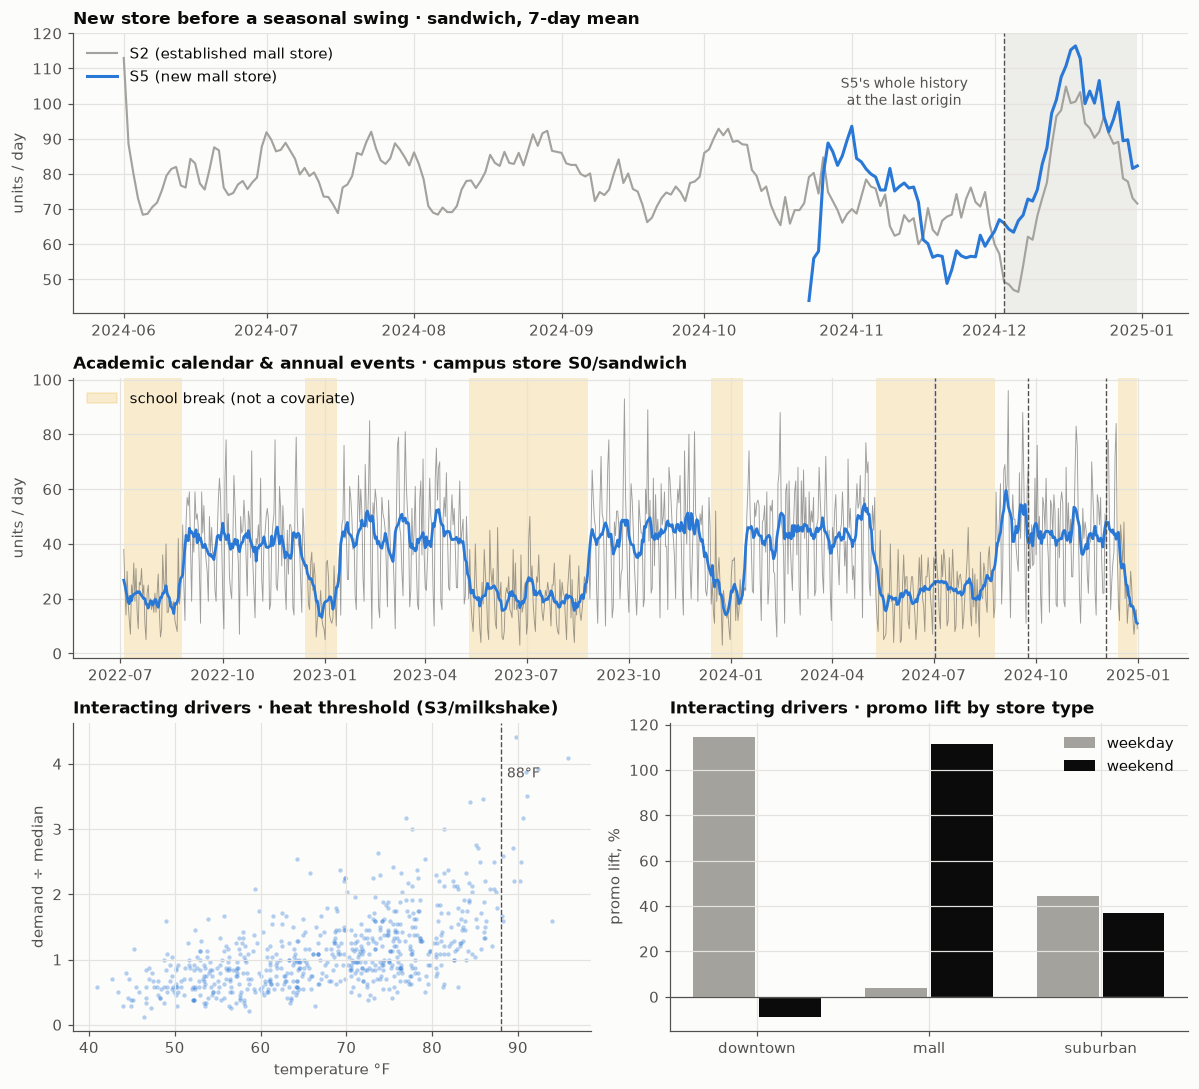

In [23]:
STRESS_SCENARIOS = [
    Scenario("seasonal_cold_start", "New store before a seasonal swing",
             "S3/S4/S5 open 41 days before origins 1/2/3, just ahead of the summer peak, the autumn drop and the "
             "December rush. Seasonality is 2× baseline, plus a holiday-shopping surge at mall and suburban stores.",
             staggered_openings=True, yearly_strength=2.0, holiday_season=0.4),
    Scenario("annual_calendar", "Academic calendar & annual events",
             "Campus (downtown) stores halve during school breaks; July 4, a state fair, holiday parties, Christmas Eve "
             "and the post-Christmas lull recur on the same dates every year. None of it is passed as a covariate.",
             annual_calendar=True),
    Scenario("nonlinear_drivers", "Interacting drivers",
             "Covariates are given but act through thresholds and interactions: promo lift depends on store type × "
             "weekday, heat matters only above ~88°F, near-freezing rain empties stores, rain only hurts on weekends.",
             promo_per_year=8, nonlinear_drivers=True),
]
SCENARIO_BY_NAME |= {s.name: s for s in STRESS_SCENARIOS}
DATA |= {s.name: simulate(s) for s in STRESS_SCENARIOS}

fig = plt.figure(figsize=(11, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.1])
ax1, ax2 = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, :])
ax3, ax4 = fig.add_subplot(gs[2, 0]), fig.add_subplot(gs[2, 1])

# (1) A new store sees six weeks; its sibling of the same type shows what comes next.
d = DATA["seasonal_cold_start"]
for uid, color, lw, label in [("S2/sandwich", "#a3a29d", 1.4, "S2 (established mall store)"),
                              ("S5/sandwich", FAMILY_COLORS["Foundation"], 2.0, "S5 (new mall store)")]:
    g = d.query("unique_id == @uid and ds >= '2024-06-01'")
    ax1.plot(g.ds, g.y.rolling(7, min_periods=1).mean(), color=color, lw=lw, label=label)
o3 = ORIGINS_ALL[2]
ax1.axvline(o3, color=INK_2, ls="--", lw=0.9)
ax1.axvspan(o3, o3 + pd.Timedelta(days=H), color=GRID, alpha=0.6, lw=0)
ax1.annotate("S5's whole history\nat the last origin", (o3 - pd.Timedelta(days=21), ax1.get_ylim()[1] * 0.9),
             ha="center", va="top", fontsize=9, color=INK_2)
ax1.set_title("New store before a seasonal swing · sandwich, 7-day mean")
ax1.set_ylabel("units / day")
ax1.legend(loc="upper left")

# (2) Campus store: the school calendar and annual events repeat every year.
g = DATA["annual_calendar"].query("unique_id == 'S0/sandwich'")
ax2.plot(g.ds, g.y, color=INK_2, lw=0.6, alpha=0.55)
ax2.plot(g.ds, g.y.rolling(7, min_periods=1, center=True).mean(), color=FAMILY_COLORS["Foundation"], lw=1.8)
off = g.off_term.to_numpy() == 1
for block in np.split(np.flatnonzero(off), np.flatnonzero(np.diff(np.flatnonzero(off)) > 1) + 1):
    if len(block):
        ax2.axvspan(g.ds.iloc[block[0]], g.ds.iloc[block[-1]], color=FAMILY_COLORS["Bayesian"], alpha=0.18, lw=0)
for o in ORIGINS:
    ax2.axvline(o, color=INK_2, ls="--", lw=0.9)
ax2.legend(handles=[Patch(color=FAMILY_COLORS["Bayesian"], alpha=0.18, label="school break (not a covariate)")], loc="upper left")
ax2.set_title("Academic calendar & annual events · campus store S0/sandwich")
ax2.set_ylabel("units / day")

# (3) Threshold: milkshake demand vs temperature.
d = DATA["nonlinear_drivers"].query("item == 'milkshake' and store == 'S3' and promo == 0 and rain == 0")
ratio = d.y / d.y.median()
ax3.scatter(d.temp, ratio, s=8, color=FAMILY_COLORS["Foundation"], alpha=0.35, lw=0)
ax3.axvline(88, color=INK_2, ls="--", lw=0.9)
ax3.annotate("88°F", (88, ratio.quantile(0.995)), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK_2)
ax3.set_xlabel("temperature °F")
ax3.set_ylabel("demand ÷ median")
ax3.set_title("Interacting drivers · heat threshold (S3/milkshake)")

# (4) Interaction: promo lift by store type and weekday.
d = DATA["nonlinear_drivers"].assign(weekend=lambda x: np.where(x.ds.dt.dayofweek >= 5, "weekend", "weekday"))
lift = (d.groupby(["store_type", "weekend", "promo"]).y.mean().unstack("promo").pipe(lambda t: t[1.0] / t[0.0] - 1)).unstack("weekend")
x = np.arange(len(lift))
for k, (col, color) in enumerate(zip(["weekday", "weekend"], ["#a3a29d", INK])):
    ax4.bar(x + (k - 0.5) * 0.38, lift[col] * 100, width=0.36, color=color, label=col)
ax4.set_xticks(x, lift.index)
ax4.axhline(0, color=INK_2, lw=0.8)
ax4.set_ylabel("promo lift, %")
ax4.set_title("Interacting drivers · promo lift by store type")
ax4.legend(loc="upper right")
fig.tight_layout()
plt.show()

### 7a. Results
Same backtest, same methods, same metrics. The cell is coloured by WQL relative to seasonal
naive within each scenario.

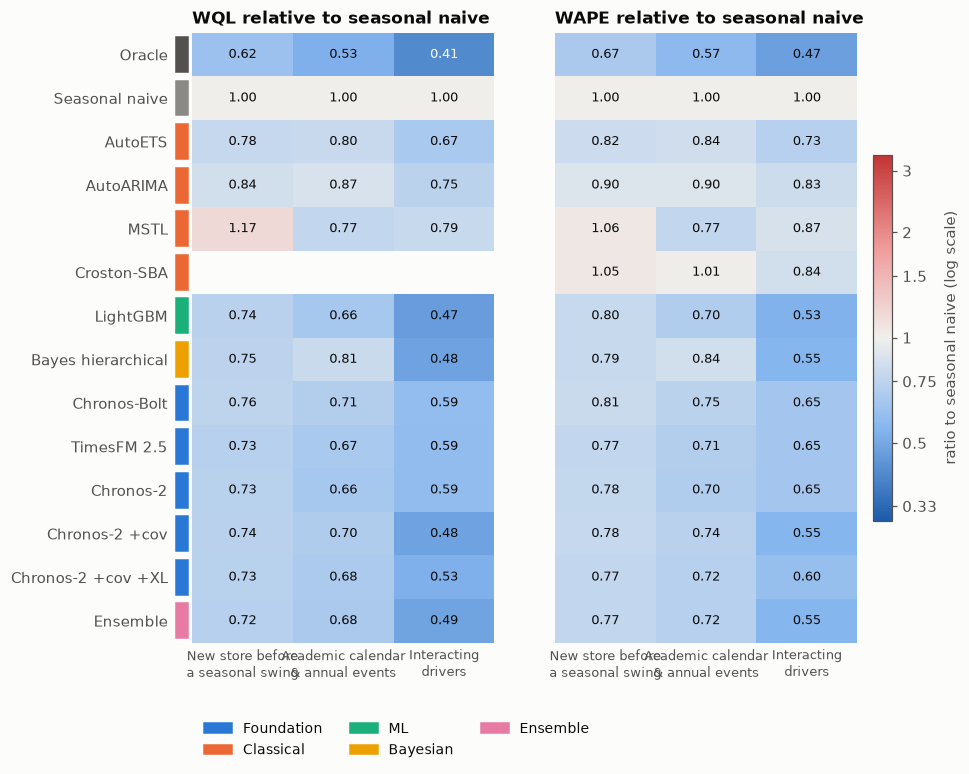

In [24]:
FORECASTS_STRESS = {sc.name: add_ensemble(run_scenario(sc)) for sc in STRESS_SCENARIOS}
SUMMARY_STRESS = pd.concat({n: summarize(fc) for n, fc in FORECASTS_STRESS.items()}, names=["scenario", "method"])
plot_relative_heatmap(SUMMARY_STRESS)

In [25]:
TSFM = [m for m, (f, _) in METHODS.items() if f == "Foundation"]


def tsfm_gap(summary):
    rows = {}
    for name, g in summary["WQL"].groupby(level="scenario"):
        g = g.droplevel("scenario").dropna()
        fm, other = g[g.index.isin(TSFM)], g[~g.index.isin(TSFM + ["Oracle"])]
        rows[SCENARIO_BY_NAME[name].title] = {
            "oracle": g["Oracle"], "best TSFM": fm.idxmin(), "TSFM WQL": fm.min(),
            "best other": other.idxmin(), "other WQL": other.min(), "TSFM gap": fm.min() / other.min() - 1,
        }
    return pd.DataFrame(rows).T



In [26]:
with pd.option_context("display.float_format", "{:.3f}".format, "display.max_columns", 50, "display.width", 250):
    for metric in ["WQL", "Cov80"]:
        print(f"\n{metric}")
        display(SUMMARY_STRESS[metric].unstack("scenario").reindex(index=METHOD_ORDER, columns=[s.name for s in STRESS_SCENARIOS]).round(3))


WQL


scenario,seasonal_cold_start,annual_calendar,nonlinear_drivers
method,,,
Oracle,0.159,0.156,0.156
Seasonal naive,0.255,0.292,0.377
AutoETS,0.200,0.234,0.253
AutoARIMA,0.214,0.255,0.281
MSTL,0.298,0.226,0.299
Croston-SBA,NaN,NaN,NaN
LightGBM,0.188,0.193,0.176
Bayes hierarchical,0.192,0.236,0.182
Chronos-Bolt,0.194,0.208,0.224



Cov80


scenario,seasonal_cold_start,annual_calendar,nonlinear_drivers
method,,,
Oracle,0.813,0.813,0.809
Seasonal naive,0.908,0.871,0.912
AutoETS,0.756,0.775,0.834
AutoARIMA,0.774,0.772,0.870
MSTL,0.332,0.512,0.662
Croston-SBA,NaN,NaN,NaN
LightGBM,0.727,0.722,0.762
Bayes hierarchical,0.742,0.696,0.809
Chronos-Bolt,0.808,0.771,0.818


### 7b. Affected vs. unaffected stores
The new stores in `seasonal_cold_start`, and the campus stores in `annual_calendar`, against the
other stores in the same scenario.

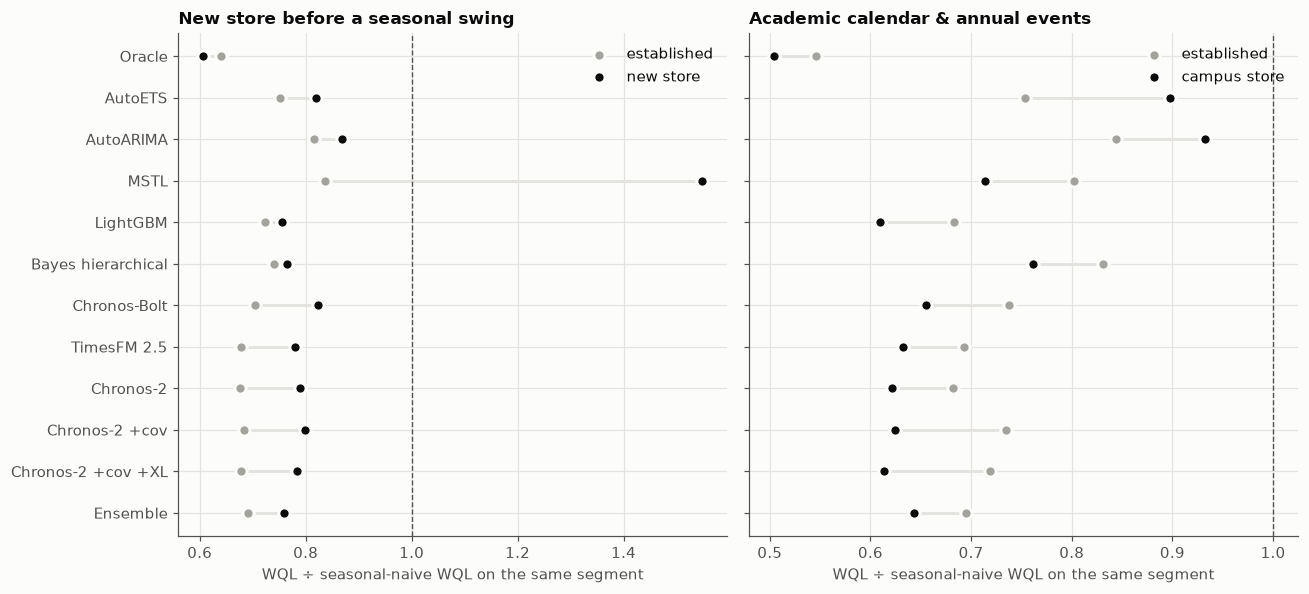

In [27]:
plot_segments(FORECASTS_STRESS, ["seasonal_cold_start", "annual_calendar"]);

### 7c. What the misses look like

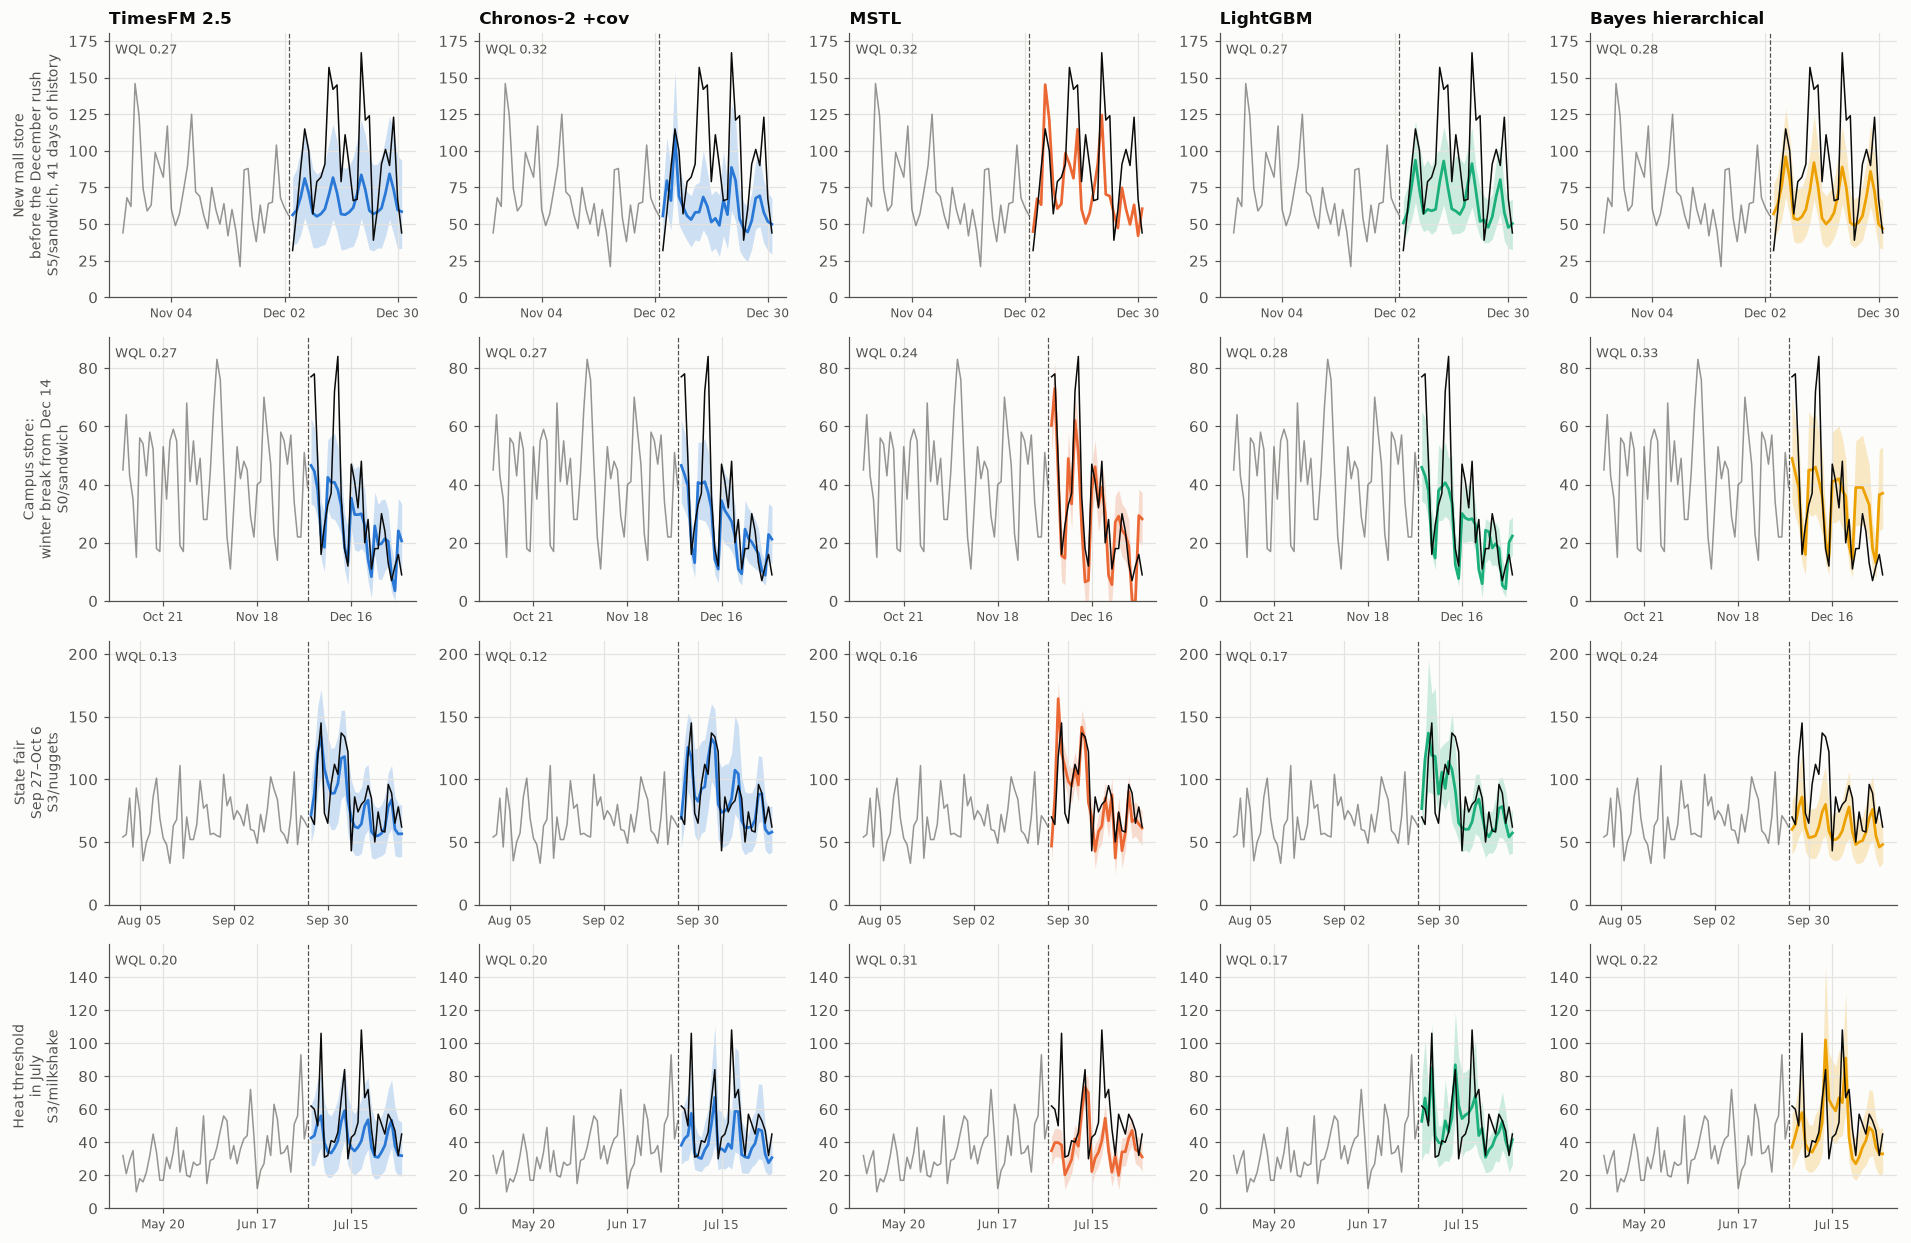

In [28]:
plot_cases(FORECASTS_STRESS, [
    ("seasonal_cold_start", "S5/sandwich", ORIGINS[-1], "New mall store\nbefore the December rush"),
    ("annual_calendar", "S0/sandwich", ORIGINS[-1], "Campus store:\nwinter break from Dec 14"),
    ("annual_calendar", "S3/nuggets", ORIGINS[min(1, len(ORIGINS) - 1)], "State fair\nSep 27–Oct 6"),
    ("nonlinear_drivers", "S3/milkshake", ORIGINS[0], "Heat threshold\nin July"),
], show=["TimesFM 2.5", "Chronos-2 +cov", "MSTL", "LightGBM", "Bayes hierarchical"])

### 7d. Is it the model or the missing information?
The calendar in `annual_calendar` was known in advance: school terms and event dates are
published. Here we re-run Chronos-2 and LightGBM on that scenario **with the calendar passed as
covariates** (`off_term`, `event_up`, `event_down`). If the TSFM gap closes, the lesson is "tell
the model what you know", not "the model can't do it".

In [29]:
CALENDAR_COVARIATES = ["off_term", "event_up", "event_down"]
calendar_path = RESULTS_DIR / "forecasts_annual_calendar_with_calendar.parquet"
if calendar_path.exists() and not RECOMPUTE:
    with_calendar = pd.read_parquet(calendar_path)
else:
    df, frames = DATA["annual_calendar"], []
    for origin in ORIGINS:
        train = df[df.ds <= origin].drop(columns="mu_true")
        test = df[(df.ds > origin) & (df.ds <= origin + pd.Timedelta(days=H))]
        future = test.drop(columns=["y", "mu_true"])
        for name, fn in {
            "Chronos-2 +cov +calendar": lambda tr, fu: _fm("chronos2", tr, fu, covariates=COVARIATES + CALENDAR_COVARIATES),
            "LightGBM +calendar": lambda tr, fu: fc_lightgbm(tr, fu, extra_covariates=CALENDAR_COVARIATES),
        }.items():
            fc = fn(train, future).merge(test[["unique_id", "ds", "y", "store", "item", "segment"]], on=["unique_id", "ds"])
            frames.append(fc.assign(method=name, origin=origin, seconds=np.nan, mase_scale=fc.unique_id.map(mase_scale(train))))
    with_calendar = pd.concat(frames, ignore_index=True)
    with_calendar.to_parquet(calendar_path)

both = pd.concat([FORECASTS_STRESS["annual_calendar"], with_calendar], ignore_index=True)
compare = ["Oracle", "MSTL", "Bayes hierarchical", "TimesFM 2.5", "Chronos-2 +cov", "Chronos-2 +cov +calendar",
           "LightGBM", "LightGBM +calendar"]
calendar_table = pd.DataFrame({
    "WQL, all stores": {m: score(both[both.method == m])["WQL"] for m in compare},
    "WQL, campus stores": {m: score(both[(both.method == m) & (both.segment == "campus store")])["WQL"] for m in compare},
    "Cov80": {m: score(both[both.method == m])["Cov80"] for m in compare},
})
display(calendar_table.round(3))

,"WQL, all stores","WQL, campus stores",Cov80
Oracle,0.156,0.165,0.813
MSTL,0.226,0.234,0.512
Bayes hierarchical,0.236,0.249,0.696
TimesFM 2.5,0.197,0.207,0.772
Chronos-2 +cov,0.204,0.204,0.704
Chronos-2 +cov +calendar,0.180,0.182,0.746
LightGBM,0.193,0.199,0.722
LightGBM +calendar,0.177,0.187,0.741


### 7e. Round 2: information only pooling or structure can supply

Round 1 mostly **refuted** the hypotheses (discussion in §7f). Being date-blind costs little when
two years of context hold last year's pattern, and 41 days was enough to pick up a new store's
weekly rhythm. So round 2 targets information that is **not in the series' own history at all**:

| Scenario | What the data does | Why TSFMs should struggle | Who should win |
|---|---|---|---|
| `price_rollout` | Prices rise 15% store by store (elasticity ≈ −1.3, so demand drops ~17%). S0/S1 went first in March 2024; then one or two stores raise prices 2 days after each origin. `log_price` is a **known covariate**. | A store raising prices for the first time has a constant price in its own history, so in-context regression has nothing to learn the effect from. | LightGBM and the Bayesian model, which learn the effect from the stores that went first. Chronos-2 with cross-learning *can* see those stores in the same batch, which is the direct test of whether that transfer works. |
| `fresh_openings` | S3/S4/S5 open just **10 days** before origins 1/2/3, with an opening buzz (+80%) that fades over a month. | Ten days is under two weekly cycles, and the context alone can't say how quickly the buzz fades. | Pooled models: the weekly rhythm comes from the store type, and the buzz decay from earlier openings (LightGBM's `age` feature). |

price_rollout | 2024-07-02 | Seasonal naive          0.0s


price_rollout | 2024-07-02 | AutoETS                 8.0s


price_rollout | 2024-07-02 | AutoARIMA              10.7s


price_rollout | 2024-07-02 | MSTL                    5.7s


price_rollout | 2024-07-02 | Croston-SBA             0.9s


...

fresh_openings | 2024-12-03 | TimesFM 2.5             1.2s


fresh_openings | 2024-12-03 | Chronos-2               0.4s


fresh_openings | 2024-12-03 | Chronos-2 +cov          1.9s


fresh_openings | 2024-12-03 | Chronos-2 +cov +XL      1.8s


fresh_openings | 2024-12-03 | Oracle                  0.3s


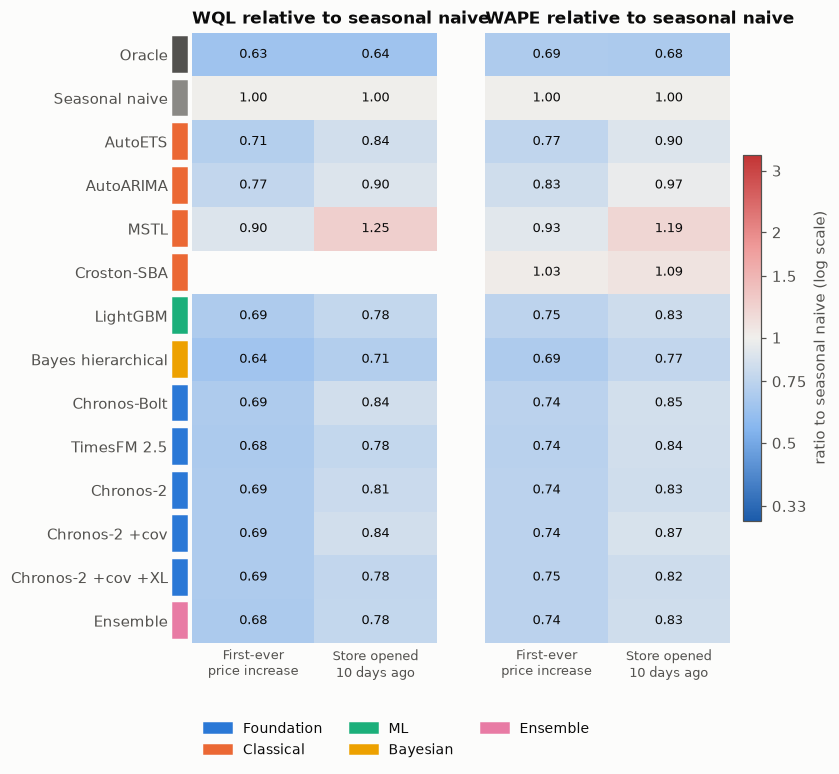

In [30]:
STRESS_2 = [
    Scenario("price_rollout", "A first-ever price increase",
             "Prices rise 15% store by store: S0/S1 in March 2024, then one or two stores 2 days after each origin. "
             "log_price is a known covariate, but the stores raising prices have no precedent in their own history.",
             price_rollout=True, extra_covariates=("log_price",)),
    Scenario("fresh_openings", "Store opened 10 days ago",
             "S3/S4/S5 open 10 days before origins 1/2/3 with an opening buzz that fades over a month.",
             fresh_openings=True),
]
SHORT_TITLES |= {"price_rollout": "First-ever\nprice increase", "fresh_openings": "Store opened\n10 days ago"}
SCENARIO_BY_NAME |= {s.name: s for s in STRESS_2}
DATA |= {s.name: simulate(s) for s in STRESS_2}
FORECASTS_STRESS |= {sc.name: add_ensemble(run_scenario(sc)) for sc in STRESS_2}
SUMMARY_STRESS = pd.concat({n: summarize(fc) for n, fc in FORECASTS_STRESS.items()}, names=["scenario", "method"])
plot_relative_heatmap(SUMMARY_STRESS.loc[[s.name for s in STRESS_2]])

The averages above mix affected and unaffected forecasts. The question is how each method does
on the forecasts the scenario is **about**: target days after a store's first price rise, and
stores that are ≤10 days old at the origin.

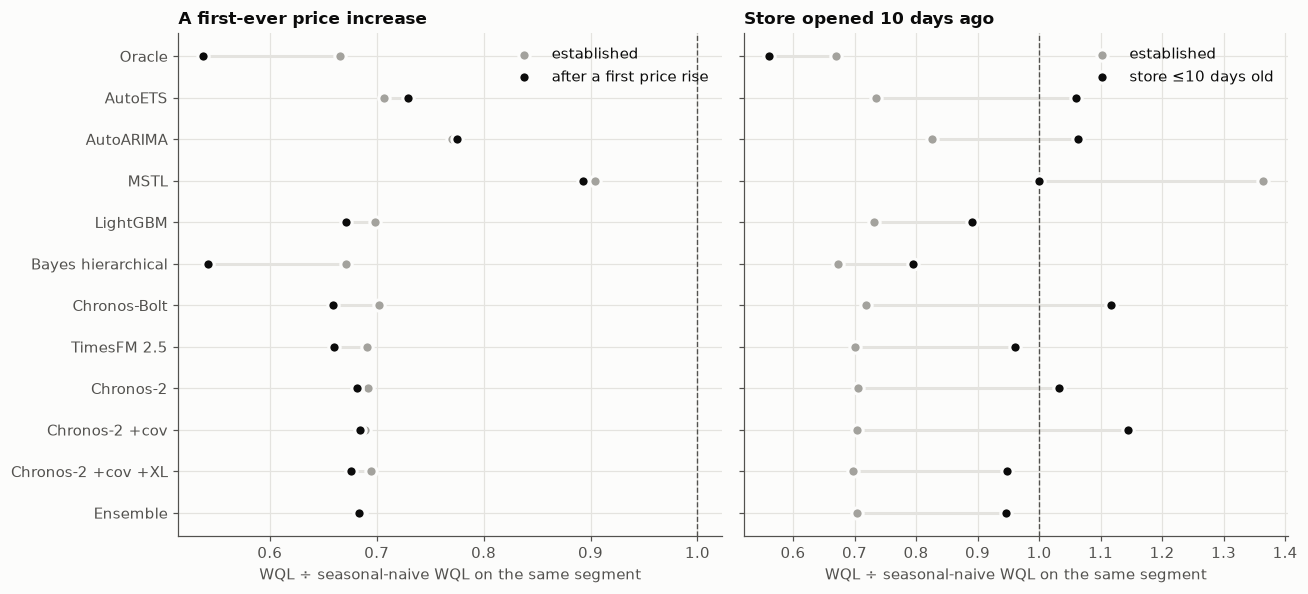

scenario,fresh_openings: WQL on affected forecasts,price_rollout: WQL on affected forecasts
method,,
Oracle,0.148,0.154
Seasonal naive,0.264,0.286
AutoETS,0.280,0.208
AutoARIMA,0.281,0.221
MSTL,0.264,0.255
LightGBM,0.236,0.192
Bayes hierarchical,0.210,0.155
Chronos-Bolt,0.295,0.188
TimesFM 2.5,0.254,0.189


In [31]:
def mark_affected(name, fc):
    d = DATA[name]
    if name == "price_rollout":
        price = d.set_index(["unique_id", "ds"]).log_price
        at_origin = price.reindex(pd.MultiIndex.from_arrays([fc.unique_id, fc.origin])).to_numpy()
        at_target = price.reindex(pd.MultiIndex.from_arrays([fc.unique_id, fc.ds])).to_numpy()
        return fc.assign(segment=np.where(at_target != at_origin, "after a first price rise", "established"))
    first_day = d.groupby("unique_id").ds.min()
    return fc.assign(segment=np.where((fc.origin - fc.unique_id.map(first_day)).dt.days <= 10, "store ≤10 days old", "established"))


AFFECTED = {s.name: mark_affected(s.name, FORECASTS_STRESS[s.name]) for s in STRESS_2}
seg2 = plot_segments(AFFECTED, [s.name for s in STRESS_2])
display(seg2[seg2.segment != "established"].pivot(index="method", columns="scenario", values="WQL")
        .reindex([m for m in METHOD_ORDER if m in seg2.method.unique()]).round(3)
        .rename(columns=lambda n: f"{n}: WQL on affected forecasts"))

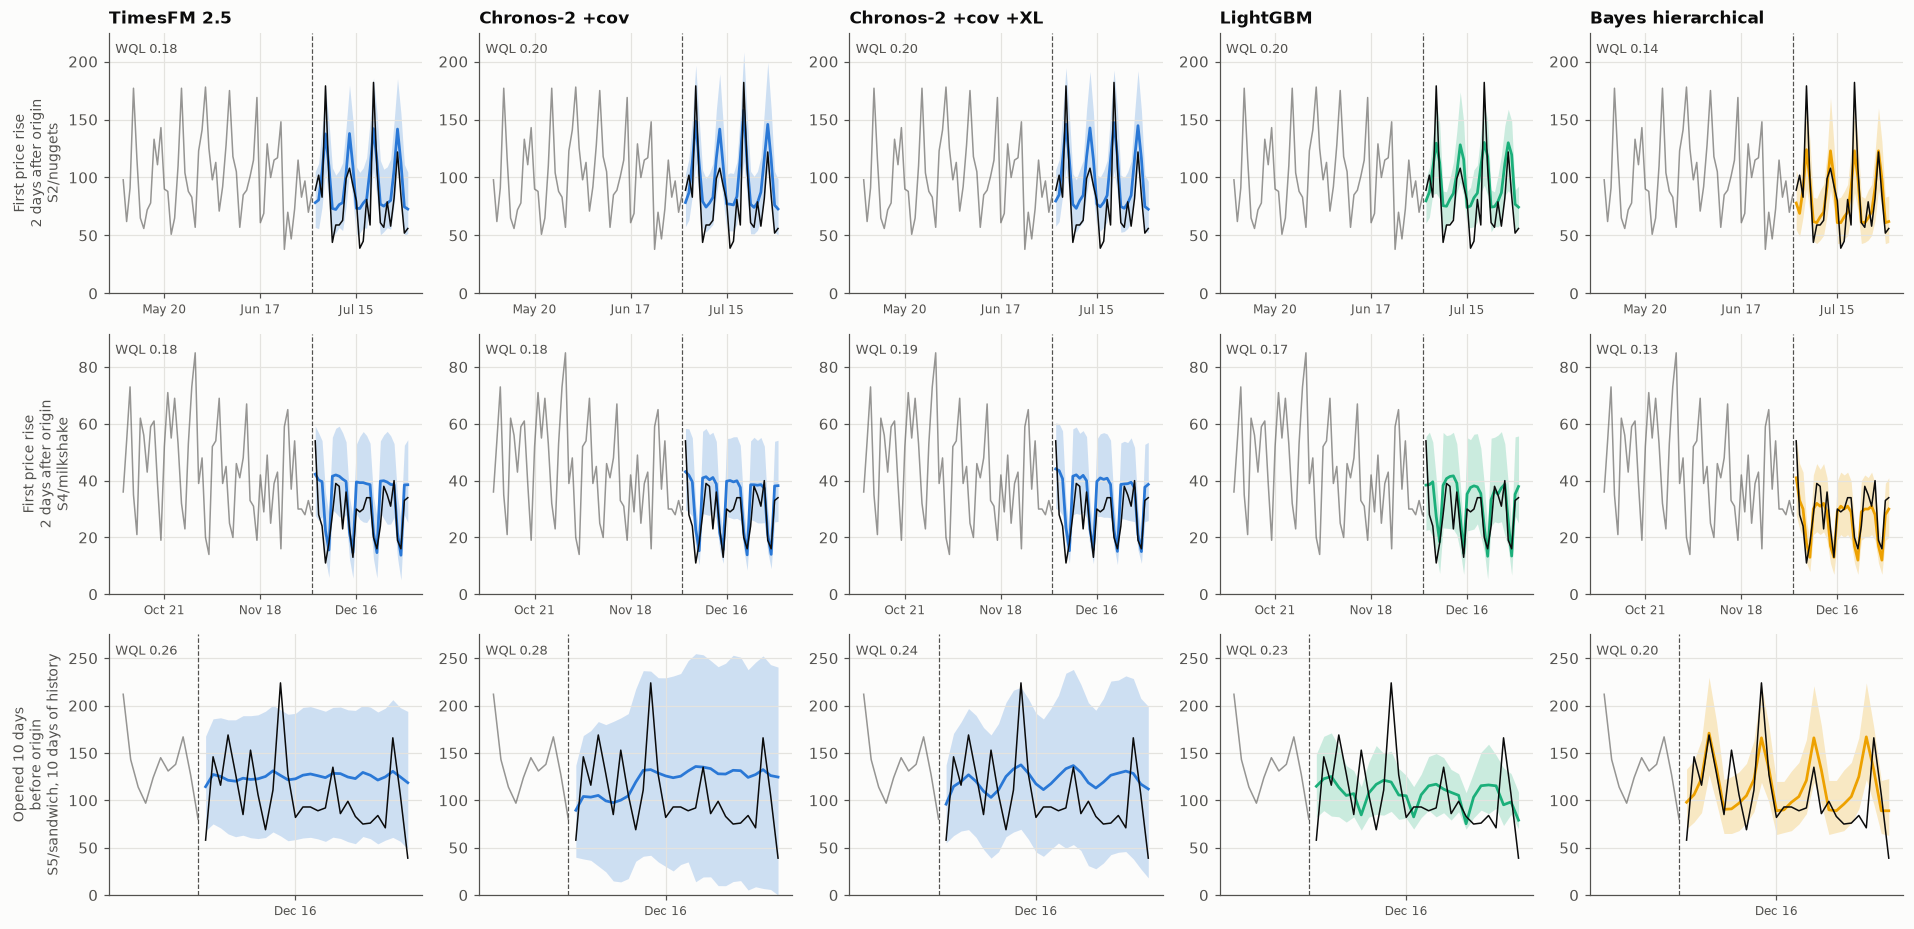

In [32]:
plot_cases(FORECASTS_STRESS, [
    ("price_rollout", "S2/nuggets", ORIGINS[0], "First price rise\n2 days after origin"),
    ("price_rollout", "S4/milkshake", ORIGINS[-1], "First price rise\n2 days after origin"),
    ("fresh_openings", "S5/sandwich", ORIGINS[-1], "Opened 10 days\nbefore origin"),
], show=["TimesFM 2.5", "Chronos-2 +cov", "Chronos-2 +cov +XL", "LightGBM", "Bayes hierarchical"])

**The foundation-model gap across every scenario**, original and stress tests: the best
foundation model against the best other method (oracle excluded), on all forecasts. A positive gap
means the best TSFM has a higher WQL than the best alternative.

In [33]:
gap = pd.concat({"original": tsfm_gap(SUMMARY), "stress test": tsfm_gap(SUMMARY_STRESS)}, names=["set", "scenario"])
display(gap.style.format({"oracle": "{:.3f}", "TSFM WQL": "{:.3f}", "other WQL": "{:.3f}", "TSFM gap": "{:+.0%}"}))

### 7f. What we found

*Numbers are WQL from the cached full run (3 origins each), with the oracle in brackets where
useful.*

**Round 1: my hypotheses were mostly wrong, which is the more interesting result.**
* **Academic calendar & annual events.** The TSFMs were among the best methods: Chronos-2 0.194
  and TimesFM 0.197, against LightGBM 0.193, MSTL 0.226 and the Bayesian model 0.236 [0.156].
  Being date-blind barely matters when two years of context contain last year's state fair and
  winter break; they find and replay the year-ago pattern (state-fair row in §7c). The method
  hurt most was the *Bayesian* model, whose smooth yearly curve cannot represent a sharp 10-day
  event or a term break. Here misspecification bit the structural model, not the TSFMs.
* Passing the calendar as covariates still helps both: Chronos-2 0.204 → 0.180 and LightGBM
  0.193 → 0.177 (§7d). Telling the model what you know is still worth doing.
* **New store before a seasonal swing.** A tie overall (TimesFM 0.185, ensemble 0.185, LightGBM
  0.188). On the new stores themselves the TSFMs pay a small penalty (0.78–0.82 of naive vs.
  0.755 for LightGBM). 41 days was enough to learn the weekly rhythm, and no method, pooled or
  not, fully anticipated the December rush.
* **Interacting drivers.** The one confirmed hypothesis, and a small one: LightGBM 0.176 vs.
  Chronos-2 +cov 0.182 (+4%). The univariate TSFMs, which never see the covariates, sit at 0.22.

**Round 2: the failures are about information that isn't in the series.**
* **First-ever price increase.** On the days after a store's first price rise, every TSFM keeps
  forecasting the old level (WQL 0.188–0.195 on those forecasts). Chronos-2 is handed `log_price`,
  and with cross-learning it sees the stores that raised prices earlier *in the same batch*. It
  still does not transfer the effect (0.193 with cross-learning vs. 0.195 without). The Bayesian
  model encodes "a price rise has the same effect at every store", learns the elasticity from the
  early stores and sits on the oracle (0.155 vs. 0.154). LightGBM (0.192) did no better than the
  TSFMs. After March almost every training row with the new price *also* has an origin after the
  change, so `log_price` looks uninformative. A feature like "price change since the origin"
  would very likely fix it, which is a reminder that the feature engineering is the model.
* **Store opened 10 days ago.** The clearest TSFM failure. With under two weekly cycles of
  context, Chronos-Bolt (0.295), Chronos-2 (0.273) and Chronos-2 +cov (0.303) do **worse than
  seasonal naive** (0.264), forecasting flat lines with very wide intervals. Cross-learning is the
  one TSFM feature that helps (0.303 → 0.250), which is what it is designed for. Pooling with
  explicit structure is better still: LightGBM 0.236, Bayesian model 0.210 [0.148].

**The pattern.** Across ten scenarios, the best TSFM came within 0–4% of the best alternative
wherever the answer is in the series' own history, even a year back. The large gaps, +7% to
+10% overall and 20–40% on the affected forecasts, all appear where the answer has to come from
*somewhere else*: other stores' experience (a price change, a new store's weekly rhythm) or an
explicit structural assumption (the elasticity is shared). Zero-shot TSFMs are very strong
pattern-continuers. They are not yet good at borrowing an *effect* from other series, even when
cross-learning puts those series in view.

**Caveats specific to this section.**
* I designed these scenarios knowing the methods. The price-rollout data has exactly the
  shared-elasticity structure the Bayesian model assumes, so its near-oracle score is the best
  case for structural modelling.
* The Bayesian fit for `fresh_openings` at the first origin had 14 divergent transitions (out of
  1,200 draws), so treat that single fit with some caution (§7 diagnostics are in
  `results/full/bayes_diagnostics_*.parquet`).
* Round 1 shows how easy it is to guess wrong about where TSFMs fail. Test, don't assume.

**Questions for discussion**
1. For the price rollout, what would it take for a TSFM to transfer the effect? Fine-tuning on
   the early stores? A covariate that encodes "change since the origin"? Or a hybrid where a
   structural model handles the intervention and the TSFM forecasts the residual?
2. How much of your real forecasting work is "continue the pattern", and how much is "apply an
   effect learned elsewhere" (new stores, price changes, menu launches)?
3. Cross-learning helped the 10-day stores but not the price change. What is different about
   the two kinds of information?

In [34]:
FM_POOL.shutdown()